In [185]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import nltk
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [186]:
df = pd.read_csv("customer_support_tickets.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [187]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8469
Number of columns: 17


In [188]:
df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a website address.\n\nPlease double check your email a...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {product_purchased}. Please assist.\n\nIf The issue I...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,"I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.\n\n1.8.3 I really I'm using the origin...",Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,"I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, please check out the Feedback. I've already contacte...",Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the delivery of the battleground game. Please have the game...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [189]:
df.tail()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
8464,8465,David Todd,adam28@example.net,22,Female,LG OLED,2021-12-08,Product inquiry,Installation support,"My {product_purchased} is making strange noises and not functioning properly. I suspect there might be a hardware issue. Can you please help me with this?\n\nAs always, you can email me at support...",Open,NaN,Low,Phone,NaN,NaN,NaN
8465,8466,Lori Davis,russell68@example.com,27,Female,Bose SoundLink Speaker,2020-02-22,Technical issue,Refund request,I'm having an issue with the {product_purchased}. Please assist.\n\n\nSell for 30-35% (I also bought a 2.5mm and I'm getting stuck).\n\n\nBuy for 80-100% ( The issue I'm facing is intermittent. So...,Open,NaN,Critical,Email,NaN,NaN,NaN
8466,8467,Michelle Kelley,ashley83@example.org,57,Female,GoPro Action Camera,2021-08-17,Technical issue,Account access,"I'm having an issue with the {product_purchased}. Please assist. You are using a different browser than the one I'm using. I've performed a factory reset on my {product_purchased}, hoping it would...",Closed,Eight account century nature kitchen.,High,Social media,2023-06-01 09:44:22,2023-06-01 04:31:22,3.0
8467,8468,Steven Rodriguez,fpowell@example.org,54,Male,PlayStation,2021-10-16,Product inquiry,Payment issue,"I'm having an issue with the {product_purchased}. Please assist. I don't think a product is in the same category as an {product_purchased}, as it wouldn't have been the issue in the case of the I'...",Closed,We seat culture plan.,Medium,Email,2023-06-01 18:28:24,2023-06-01 05:32:24,3.0
8468,8469,Steven Davis MD,lori20@example.net,53,Other,Philips Hue Lights,2020-06-01,Billing inquiry,Hardware issue,"There seems to be a hardware problem with my {product_purchased}. The screen is flickering, and I'm unable to use it. What should I do? I'll try my best to fix it now.\n\nI could get a I've review...",Open,NaN,High,Phone,NaN,NaN,NaN


In [190]:
df.columns

Index(['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age',
       'Customer Gender', 'Product Purchased', 'Date of Purchase',
       'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status',
       'Resolution', 'Ticket Priority', 'Ticket Channel',
       'First Response Time', 'Time to Resolution',
       'Customer Satisfaction Rating'],
      dtype='object')

In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priority               8469 non-null   object 
 13  Tic

In [192]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Ticket ID,8469.0,NaN,NaN,NaN,4235.0,2444.934048,1.0,2118.0,4235.0,6352.0,8469.0
Customer Name,8469,8028,Michael Garcia,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Email,8469,8320,asmith@example.com,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,8469.0,NaN,NaN,NaN,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Gender,8469,3,Male,2896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Purchased,8469,42,Canon EOS,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Purchase,8469,730,2020-10-21,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Type,8469,5,Refund request,1752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Subject,8469,16,Refund request,576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Description,8469,8077,I'm having an issue with the {product_purchased}. Please assist. This problem started occurring after the recent software update. I haven't made any other changes to the device.,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [193]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticket ID,8469.0,4235.000000,2444.934048,1.0,2118.0,4235.0,6352.0,8469.0
Customer Age,8469.0,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Satisfaction Rating,2769.0,2.991333,1.407016,1.0,2.0,3.0,4.0,5.0


In [194]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [195]:
df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (8469, 17)


In [196]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_table = missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_table

,Missing Values,Missing Percentage
Customer Satisfaction Rating,5700,67.304286
Resolution,5700,67.304286
Time to Resolution,5700,67.304286
First Response Time,2819,33.286102
Ticket ID,0,0.000000
Customer Name,0,0.000000
Customer Email,0,0.000000
Customer Age,0,0.000000
Customer Gender,0,0.000000
Ticket Subject,0,0.000000


In [197]:
df["Ticket Type"].value_counts()

Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

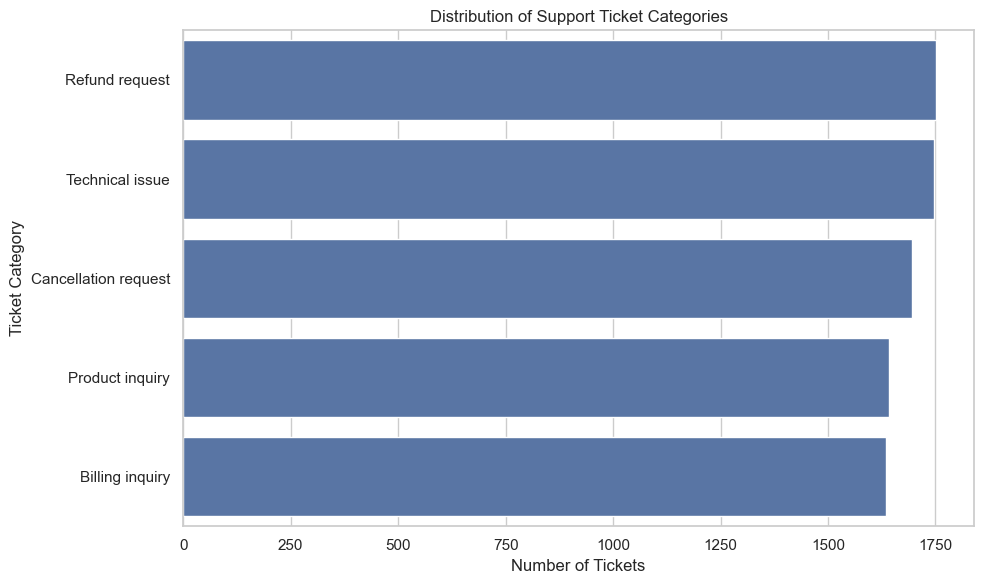

In [198]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="Ticket Type",
    order=df["Ticket Type"].value_counts().index
)

plt.title("Distribution of Support Ticket Categories")
plt.xlabel("Number of Tickets")
plt.ylabel("Ticket Category")

plt.tight_layout()
plt.show()

In [199]:
df["Ticket Priority"].value_counts()

Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64

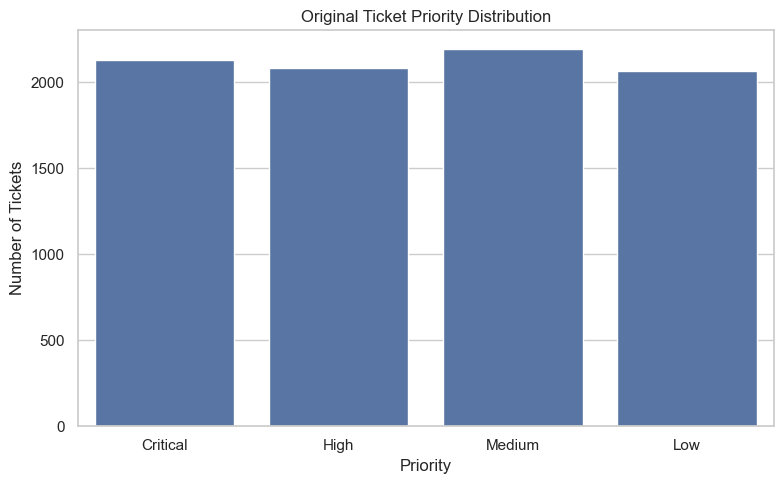

In [200]:
plt.figure(figsize=(8, 5))

priority_order = ["Critical", "High", "Medium", "Low"]

sns.countplot(
    data=df,
    x="Ticket Priority",
    order=priority_order
)

plt.title("Original Ticket Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

In [201]:
priority_mapping = {
    "Critical": "High",
    "High": "High",
    "Medium": "Medium",
    "Low": "Low"
}

df["Priority"] = df["Ticket Priority"].map(priority_mapping)

In [202]:
df["Priority"].value_counts()

Priority
High      4214
Medium    2192
Low       2063
Name: count, dtype: int64

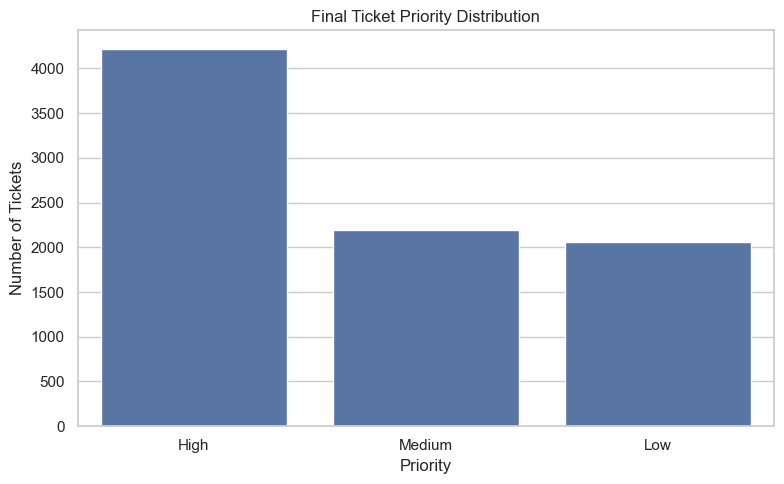

In [203]:
plt.figure(figsize=(8, 5))

priority_order = ["High", "Medium", "Low"]

sns.countplot(
    data=df,
    x="Priority",
    order=priority_order
)

plt.title("Final Ticket Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

In [204]:
df["Ticket Channel"].value_counts()

Ticket Channel
Email           2143
Phone           2132
Social media    2121
Chat            2073
Name: count, dtype: int64

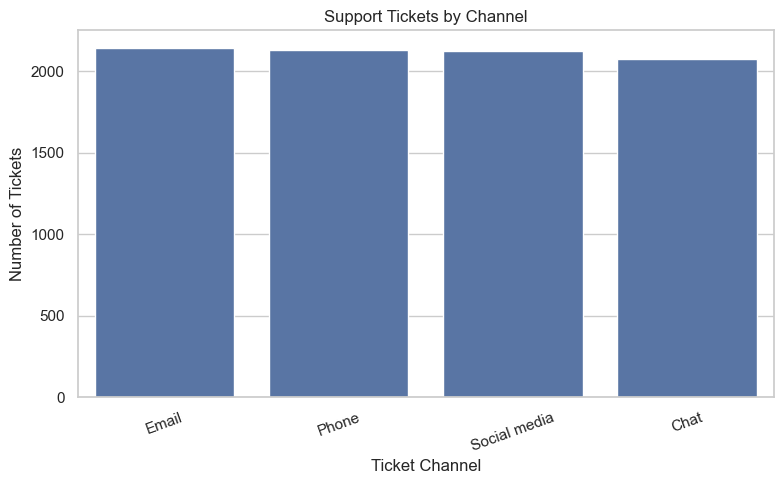

In [205]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Ticket Channel",
    order=df["Ticket Channel"].value_counts().index
)

plt.title("Support Tickets by Channel")
plt.xlabel("Ticket Channel")
plt.ylabel("Number of Tickets")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

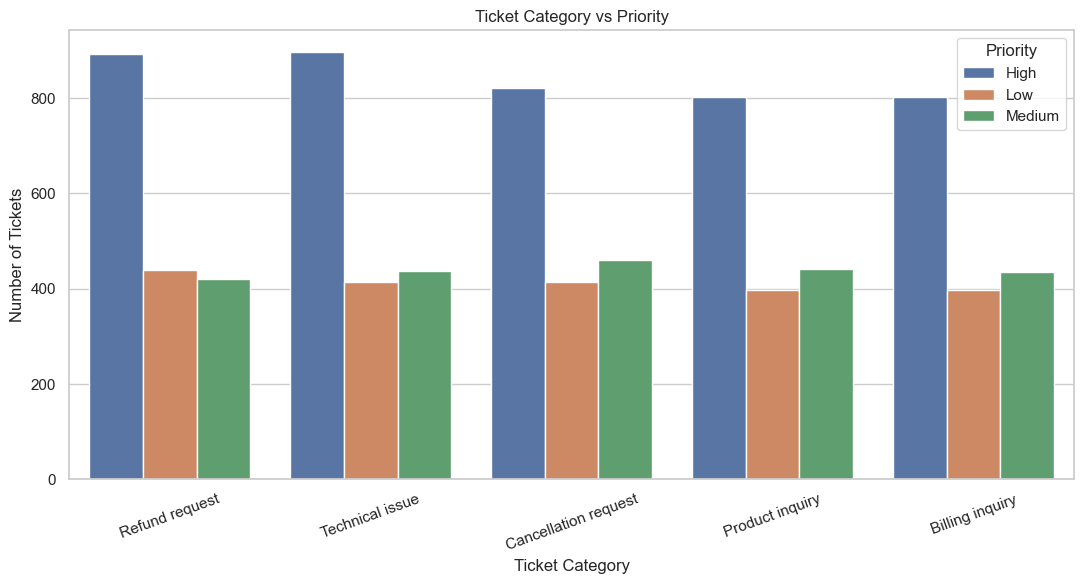

In [206]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x="Ticket Type",
    hue="Priority",
    order=df["Ticket Type"].value_counts().index
)

plt.title("Ticket Category vs Priority")
plt.xlabel("Ticket Category")
plt.ylabel("Number of Tickets")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [207]:
priority_percentage = pd.crosstab(
    df["Ticket Type"],
    df["Priority"],
    normalize="index"
) * 100

priority_percentage

Priority,High,Low,Medium
Ticket Type,,,
Billing inquiry,49.082007,24.357405,26.560588
Cancellation request,48.436578,24.424779,27.138643
Product inquiry,48.872639,24.253504,26.873857
Refund request,50.913242,25.114155,23.972603
Technical issue,51.345163,23.640527,25.014310


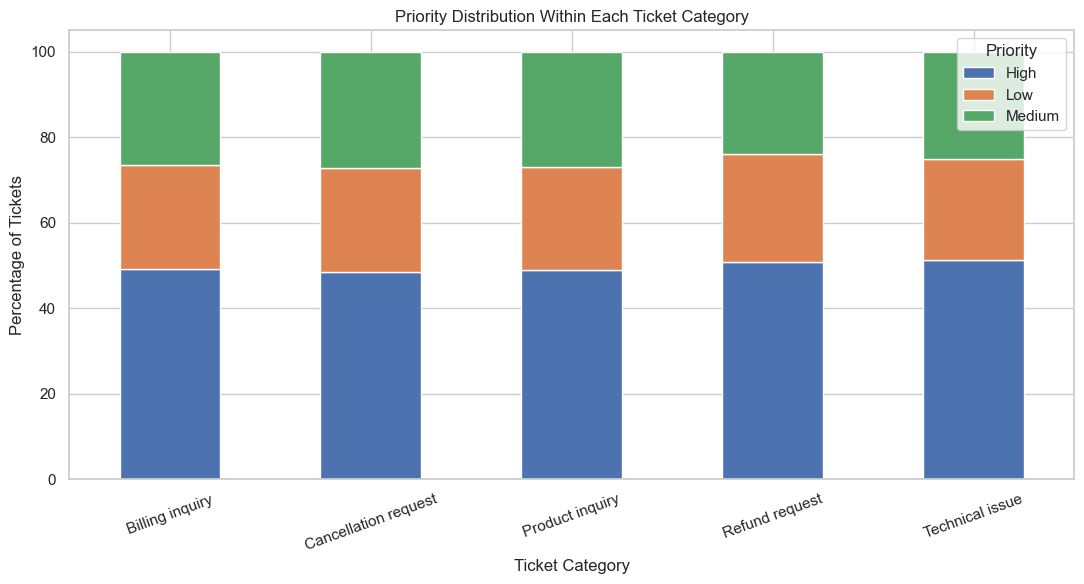

In [208]:
priority_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Priority Distribution Within Each Ticket Category")
plt.xlabel("Ticket Category")
plt.ylabel("Percentage of Tickets")

plt.xticks(rotation=20)
plt.legend(title="Priority")

plt.tight_layout()
plt.show()

In [209]:
df["Description_Length"] = df["Ticket Description"].str.len()

In [210]:
df["Description_Word_Count"] = (
    df["Ticket Description"]
    .str.split()
    .str.len()
)

In [211]:
df[
    [
        "Ticket Description",
        "Description_Length",
        "Description_Word_Count"
    ]
].head()

,Ticket Description,Description_Length,Description_Word_Count
0,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a website address.\n\nPlease double check your email a...,284,43
1,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {product_purchased}. Please assist.\n\nIf The issue I...,282,44
2,"I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.\n\n1.8.3 I really I'm using the origin...",275,42
3,"I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, please check out the Feedback. I've already contacte...",262,41
4,I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the delivery of the battleground game. Please have the game...,333,55


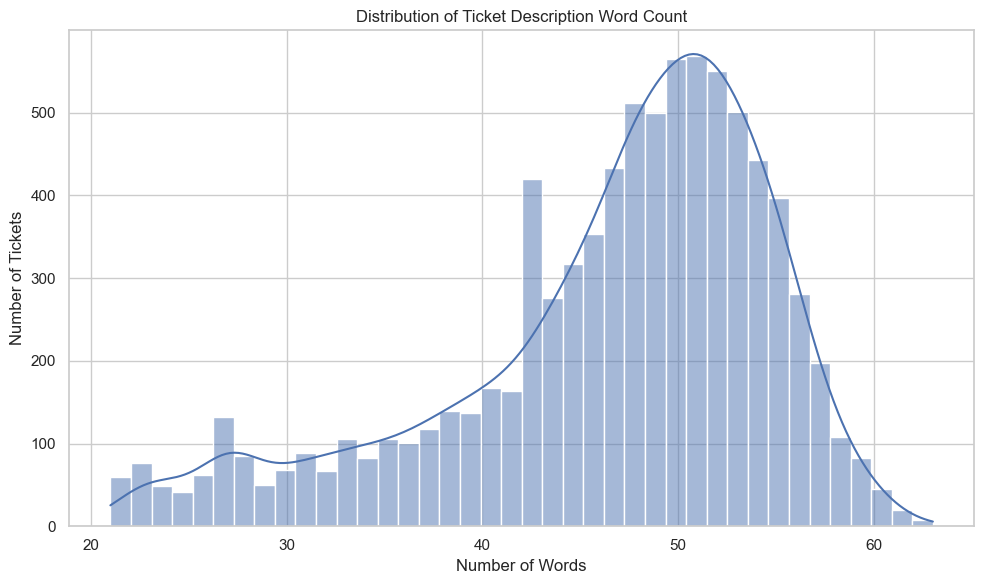

In [212]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Description_Word_Count",
    bins=40,
    kde=True
)

plt.title("Distribution of Ticket Description Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

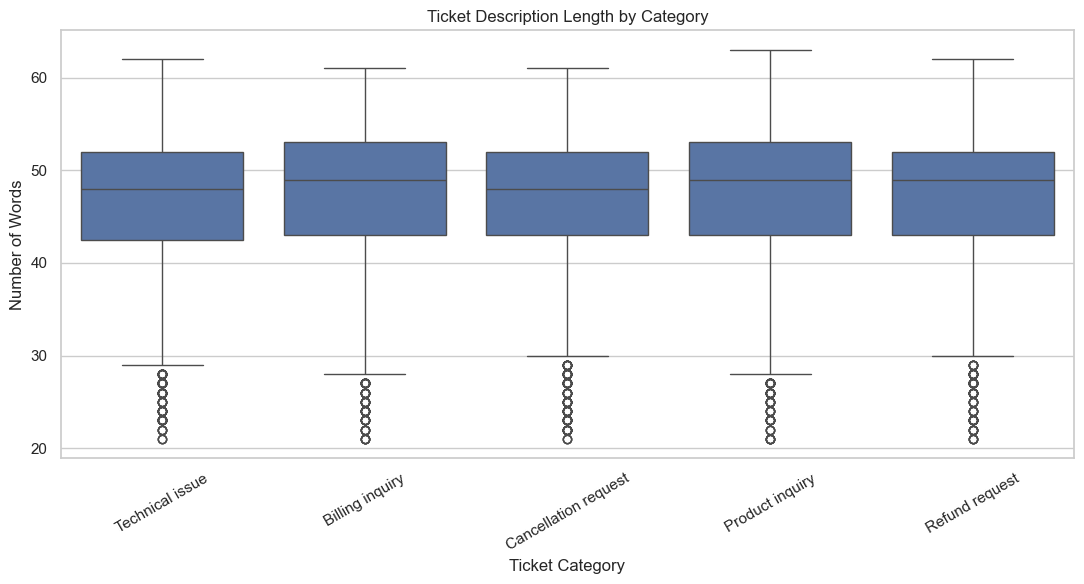

In [213]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Ticket Type",
    y="Description_Word_Count"
)

plt.title("Ticket Description Length by Category")
plt.xlabel("Ticket Category")
plt.ylabel("Number of Words")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

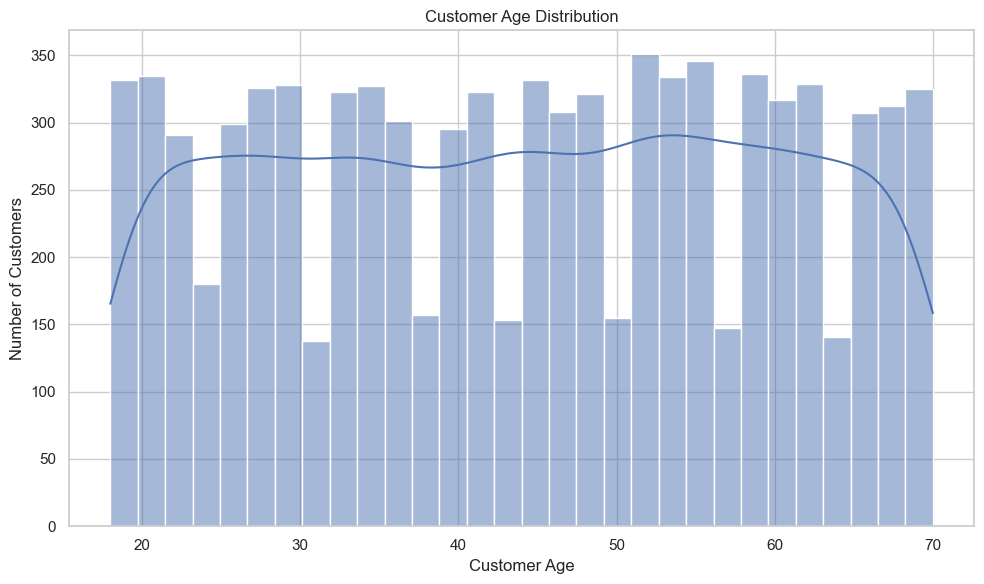

In [214]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Customer Age",
    bins=30,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [215]:
df["Customer Satisfaction Rating"].value_counts().sort_index()

Customer Satisfaction Rating
1.0    553
2.0    549
3.0    580
4.0    543
5.0    544
Name: count, dtype: int64

In [216]:
satisfaction_by_type = (
    df.groupby("Ticket Type")["Customer Satisfaction Rating"]
    .mean()
    .sort_values(ascending=False)
)

satisfaction_by_type

Ticket Type
Cancellation request    3.029070
Billing inquiry         3.027574
Product inquiry         3.016886
Technical issue         2.958621
Refund request          2.934564
Name: Customer Satisfaction Rating, dtype: float64

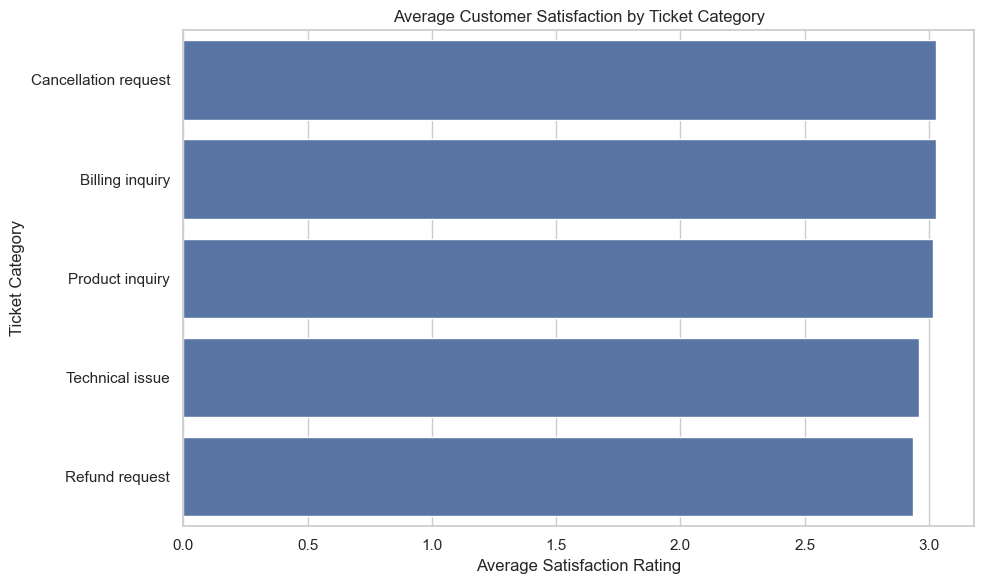

In [217]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=satisfaction_by_type.values,
    y=satisfaction_by_type.index
)

plt.title("Average Customer Satisfaction by Ticket Category")
plt.xlabel("Average Satisfaction Rating")
plt.ylabel("Ticket Category")

plt.tight_layout()
plt.show()

In [218]:
top_products = df["Product Purchased"].value_counts().head(10)

top_products

Product Purchased
Canon EOS              240
GoPro Hero             228
Nest Thermostat        225
Amazon Echo            221
Philips Hue Lights     221
LG Smart TV            219
Sony Xperia            217
Roomba Robot Vacuum    216
Apple AirPods          213
LG OLED                213
Name: count, dtype: int64

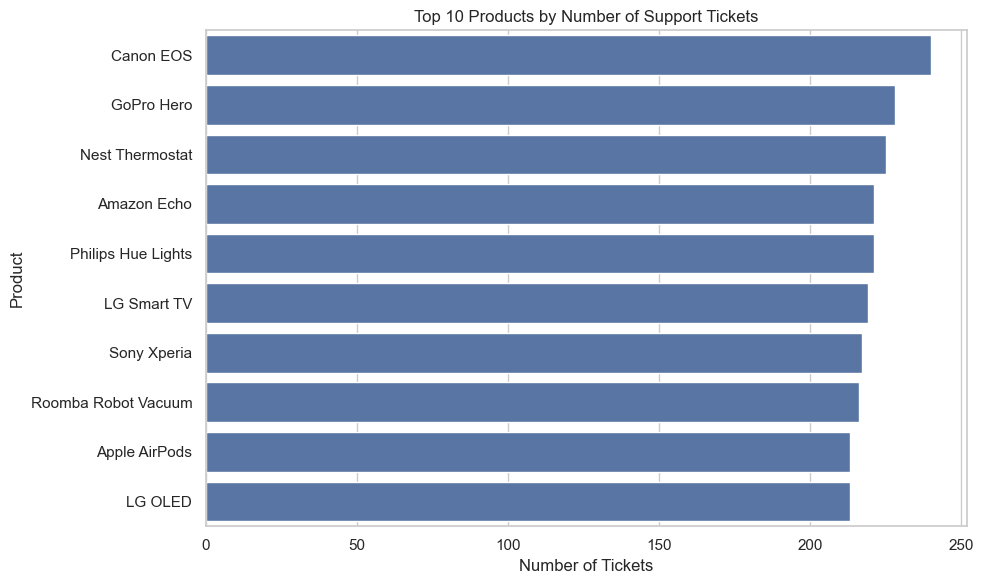

In [219]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Products by Number of Support Tickets")
plt.xlabel("Number of Tickets")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [220]:
df["Ticket_Text"] = (
    df["Ticket Subject"].fillna("") 
    + " " 
    + df["Ticket Description"].fillna("")
)
df[
    ["Ticket Subject", "Ticket Description", "Ticket_Text"]
].head()

,Ticket Subject,Ticket Description,Ticket_Text
0,Product setup,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a website address.\n\nPlease double check your email a...,Product setup I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a website address.\n\nPlease double chec...
1,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {product_purchased}. Please assist.\n\nIf The issue I...,Peripheral compatibility I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {product_purchased}. Please ...
2,Network problem,"I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.\n\n1.8.3 I really I'm using the origin...","Network problem I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.\n\n1.8.3 I really I'm ..."
3,Account access,"I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, please check out the Feedback. I've already contacte...","Account access I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, please check out the Feedback. I've a..."
4,Data loss,I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the delivery of the battleground game. Please have the game...,Data loss I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the delivery of the battleground game. Please hav...


In [221]:
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anush\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [222]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print("Number of stopwords:", len(stop_words))

Number of stopwords: 198


In [223]:
def clean_text(text):
    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stopwords
    words = [
        word for word in text.split()
        if word not in stop_words
    ]

    return " ".join(words)

In [224]:
df["Clean_Text"] = df["Ticket_Text"].apply(clean_text)

In [225]:
df[
    ["Ticket_Text", "Clean_Text"]
].head(10)

,Ticket_Text,Clean_Text
0,Product setup I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a website address.\n\nPlease double chec...,product setup im issue productpurchased please assist billing zip code appreciate requested website address please double check email address ive tried troubleshooting steps mentioned user manual ...
1,Peripheral compatibility I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {product_purchased}. Please ...,peripheral compatibility im issue productpurchased please assist need change existing product im issue productpurchased please assist issue im facing intermittent sometimes works fine times acts u...
2,"Network problem I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.\n\n1.8.3 I really I'm ...",network problem im facing problem productpurchased productpurchased turning working fine yesterday doesnt respond really im using original charger came productpurchased charging properly
3,"Account access I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, please check out the Feedback. I've a...",account access im issue productpurchased please assist problem youre interested id love see happen please check feedback ive already contacted customer support multiple times issue remains unresolved
4,Data loss I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the delivery of the battleground game. Please hav...,data loss im issue productpurchased please assist note seller responsible damages arising delivery battleground game please game good condition shipped ive noticed sudden decrease battery life pro...
5,"Payment issue I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond. To remove the new {produ...",payment issue im facing problem productpurchased productpurchased turning working fine yesterday doesnt respond remove new productpurch ive checked available software updates productpurchased none
6,"Refund request I'm unable to access my {product_purchased} account. It keeps displaying an 'Invalid Credentials' error, even though I'm using the correct login information. How can I regain access...",refund request im unable access productpurchased account keeps displaying invalid credentials error even though im using correct login information regain access account solution im unable find opt...
7,Battery life I'm having an issue with the {product_purchased}. Please assist. (Thanks) I will contact all my suppliers and confirm.\n\nPlease try and find out whether their inventory is currently ...,battery life im issue productpurchased please assist thanks contact suppliers confirm please try find whether inventory currently stocked reason ive performed factory reset productpurchased hoping...
8,"Installation support I'm having an issue with the {product_purchased}. Please assist. Thank you.\n\n{product_purchased} is not the exact type you might prefer, they use the exact same method for d...",installation support im issue productpurchased please assist thank productpurchased exact type might prefer use exact method different uses please help ive recently updated firmware productpurchas...
9,"Payment issue My {product_purchased} is making strange noises and not functioning properly. I suspect there might be a hardware issue. Can you please help me with this?\n\n} If we can, please send...",payment issue productpurchased making strange noises functioning properly suspect might hardware issue please help please send request dav issue im facing inter

In [226]:
empty_text = (df["Clean_Text"].str.strip() == "").sum()

print("Empty text records:", empty_text)

Empty text records: 0


In [227]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priority               8469 non-null   object 
 13  Tic

In [228]:
df[
    [
        "Ticket Type",
        "Ticket Priority",
        "Priority",
        "Ticket_Text",
        "Clean_Text"
    ]
].head()

,Ticket Type,Ticket Priority,Priority,Ticket_Text,Clean_Text
0,Technical issue,Critical,High,Product setup I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a website address.\n\nPlease double chec...,product setup im issue productpurchased please assist billing zip code appreciate requested website address please double check email address ive tried troubleshooting steps mentioned user manual ...
1,Technical issue,Critical,High,Peripheral compatibility I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {product_purchased}. Please ...,peripheral compatibility im issue productpurchased please assist need change existing product im issue productpurchased please assist issue im facing intermittent sometimes works fine times acts u...
2,Technical issue,Low,Low,"Network problem I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.\n\n1.8.3 I really I'm ...",network problem im facing problem productpurchased productpurchased turning working fine yesterday doesnt respond really im using original charger came productpurchased charging properly
3,Billing inquiry,Low,Low,"Account access I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, please check out the Feedback. I've a...",account access im issue productpurchased please assist problem youre interested id love see happen please check feedback ive already contacted customer support multiple times issue remains unresolved
4,Billing inquiry,Low,Low,Data loss I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the delivery of the battleground game. Please hav...,data loss im issue productpurchased please assist note seller responsible damages arising delivery battleground game please game good condition shipped ive noticed sudden decrease battery life pro...


In [229]:
text_features = df["Clean_Text"]
category_target = df["Ticket Type"]
priority_target = df["Priority"]

In [230]:
df.to_csv("customer_support_tickets_preprocessed.csv",
    index=False
)

print("Preprocessed dataset saved successfully.")

Preprocessed dataset saved successfully.


<h2>Stage 2</h2>

In [231]:
from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Stage 2 libraries imported successfully.")

Stage 2 libraries imported successfully.


In [232]:
print("Text column:", "Clean_Text")
print("Category target:", "Ticket Type")
print("Priority target:", "Priority")

print("\nMissing values:")
print("Clean_Text:", df["Clean_Text"].isnull().sum())
print("Ticket Type:", df["Ticket Type"].isnull().sum())
print("Priority:", df["Priority"].isnull().sum())

Text column: Clean_Text
Category target: Ticket Type
Priority target: Priority

Missing values:
Clean_Text: 0
Ticket Type: 0
Priority: 0


In [233]:
X = df["Clean_Text"]

y_category = df["Ticket Type"]

y_priority = df["Priority"]

In [234]:
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

print("Category Training samples:", len(X_train_cat))
print("Category Testing samples:", len(X_test_cat))

Category Training samples: 6775
Category Testing samples: 1694


In [235]:
X_train_pri, X_test_pri, y_train_pri, y_test_pri = train_test_split(
    X,
    y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_priority
)

print("Priority Training samples:", len(X_train_pri))
print("Priority Testing samples:", len(X_test_pri))

Priority Training samples: 6775
Priority Testing samples: 1694


In [236]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [237]:
X_train_cat_tfidf = tfidf.fit_transform(X_train_cat)
X_test_cat_tfidf = tfidf.transform(X_test_cat)

In [238]:
print("Training TF-IDF shape:", X_train_cat_tfidf.shape)
print("Testing TF-IDF shape:", X_test_cat_tfidf.shape)

Training TF-IDF shape: (6775, 8552)
Testing TF-IDF shape: (1694, 8552)


In [239]:
feature_names = tfidf.get_feature_names_out()

print("Number of TF-IDF features:", len(feature_names))
print("\nFirst 50 features:")
print(feature_names[:50])

Number of TF-IDF features: 8552

First 50 features:
['ability' 'able' 'able add' 'able answer' 'able contact' 'able find'
 'able fix' 'able get' 'able go' 'able help' 'able im' 'able install'
 'able ive' 'able make' 'able obtain' 'able play' 'able purchase'
 'able receive' 'able see' 'able sell' 'able ship' 'able take' 'able use'
 'able view' 'absolutely' 'accept' 'accept payment' 'accepted'
 'accepted please' 'accepting' 'access' 'access account' 'access im'
 'access ive' 'access product' 'access productpurchased' 'access products'
 'access seems' 'accessible' 'accessories' 'accessories ive'
 'accidentally' 'accidentally deleted' 'according' 'account'
 'account access' 'account account' 'account active' 'account add'
 'account always']


In [240]:
nb_category = MultinomialNB()

In [241]:
nb_category.fit(
    X_train_cat_tfidf,
    y_train_cat
)

MultinomialNB()

In [242]:
y_pred_nb_cat = nb_category.predict(
    X_test_cat_tfidf
)

In [243]:
lr_category = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_category.fit(
    X_train_cat_tfidf,
    y_train_cat
)

y_pred_lr_cat = lr_category.predict(
    X_test_cat_tfidf
)

In [244]:
svm_category = LinearSVC(
    random_state=42
)

svm_category.fit(
    X_train_cat_tfidf,
    y_train_cat
)

y_pred_svm_cat = svm_category.predict(
    X_test_cat_tfidf
)

In [245]:
def evaluate_model(model_name, y_true, y_pred):
    
    accuracy = accuracy_score(y_true, y_pred)
    
    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
    
    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
    
    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
    
    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

In [246]:
category_results = []

category_results.append(
    evaluate_model(
        "Naive Bayes",
        y_test_cat,
        y_pred_nb_cat
    )
)

category_results.append(
    evaluate_model(
        "Logistic Regression",
        y_test_cat,
        y_pred_lr_cat
    )
)

category_results.append(
    evaluate_model(
        "Linear SVM",
        y_test_cat,
        y_pred_svm_cat
    )
)

In [247]:
category_results_df = pd.DataFrame(category_results)

category_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.204250,0.203108,0.202618,0.199038
1,Logistic Regression,0.209563,0.209556,0.209429,0.209379
2,Linear SVM,0.201299,0.201650,0.201465,0.201530


In [248]:
print("NAIVE BAYES - CATEGORY")
print(
    classification_report(
        y_test_cat,
        y_pred_nb_cat,
        zero_division=0
    )
)

NAIVE BAYES - CATEGORY
                      precision    recall  f1-score   support

     Billing inquiry       0.20      0.13      0.16       327
Cancellation request       0.21      0.18      0.19       339
     Product inquiry       0.19      0.16      0.18       328
      Refund request       0.19      0.24      0.21       351
     Technical issue       0.22      0.30      0.26       349

            accuracy                           0.20      1694
           macro avg       0.20      0.20      0.20      1694
        weighted avg       0.20      0.20      0.20      1694



In [249]:
print("LOGISTIC REGRESSION - CATEGORY")
print(
    classification_report(
        y_test_cat,
        y_pred_lr_cat,
        zero_division=0
    )
)

LOGISTIC REGRESSION - CATEGORY
                      precision    recall  f1-score   support

     Billing inquiry       0.22      0.21      0.22       327
Cancellation request       0.20      0.19      0.20       339
     Product inquiry       0.21      0.20      0.20       328
      Refund request       0.17      0.18      0.18       351
     Technical issue       0.24      0.26      0.25       349

            accuracy                           0.21      1694
           macro avg       0.21      0.21      0.21      1694
        weighted avg       0.21      0.21      0.21      1694



In [250]:
print("LINEAR SVM - CATEGORY")
print(
    classification_report(
        y_test_cat,
        y_pred_svm_cat,
        zero_division=0
    )
)

LINEAR SVM - CATEGORY
                      precision    recall  f1-score   support

     Billing inquiry       0.21      0.21      0.21       327
Cancellation request       0.19      0.19      0.19       339
     Product inquiry       0.22      0.21      0.21       328
      Refund request       0.17      0.18      0.18       351
     Technical issue       0.22      0.22      0.22       349

            accuracy                           0.20      1694
           macro avg       0.20      0.20      0.20      1694
        weighted avg       0.20      0.20      0.20      1694



In [251]:
tfidf_priority = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [252]:
X_train_pri_tfidf = tfidf_priority.fit_transform(
    X_train_pri
)

X_test_pri_tfidf = tfidf_priority.transform(
    X_test_pri
)

In [253]:
print("Priority training TF-IDF shape:", X_train_pri_tfidf.shape)
print("Priority testing TF-IDF shape:", X_test_pri_tfidf.shape)

Priority training TF-IDF shape: (6775, 8584)
Priority testing TF-IDF shape: (1694, 8584)


In [254]:
nb_priority = MultinomialNB()

nb_priority.fit(
    X_train_pri_tfidf,
    y_train_pri
)

y_pred_nb_pri = nb_priority.predict(
    X_test_pri_tfidf
)

In [255]:
lr_priority = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_priority.fit(
    X_train_pri_tfidf,
    y_train_pri
)

y_pred_lr_pri = lr_priority.predict(
    X_test_pri_tfidf
)

In [256]:
svm_priority = LinearSVC(
    random_state=42
)

svm_priority.fit(
    X_train_pri_tfidf,
    y_train_pri
)

y_pred_svm_pri = svm_priority.predict(
    X_test_pri_tfidf
)

In [257]:
priority_results = []

priority_results.append(
    evaluate_model(
        "Naive Bayes",
        y_test_pri,
        y_pred_nb_pri
    )
)

priority_results.append(
    evaluate_model(
        "Logistic Regression",
        y_test_pri,
        y_pred_lr_pri
    )
)

priority_results.append(
    evaluate_model(
        "Linear SVM",
        y_test_pri,
        y_pred_svm_pri
    )
)

In [258]:
priority_results_df = pd.DataFrame(priority_results)

priority_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.495277,0.165483,0.331752,0.220819
1,Logistic Regression,0.472845,0.310910,0.328475,0.254713
2,Linear SVM,0.431523,0.336149,0.336048,0.319121


In [259]:
print("NAIVE BAYES - PRIORITY")
print(
    classification_report(
        y_test_pri,
        y_pred_nb_pri,
        zero_division=0
    )
)

NAIVE BAYES - PRIORITY
              precision    recall  f1-score   support

        High       0.50      1.00      0.66       843
         Low       0.00      0.00      0.00       413
      Medium       0.00      0.00      0.00       438

    accuracy                           0.50      1694
   macro avg       0.17      0.33      0.22      1694
weighted avg       0.25      0.50      0.33      1694



In [260]:
print("LOGISTIC REGRESSION - PRIORITY")
print(
    classification_report(
        y_test_pri,
        y_pred_lr_pri,
        zero_division=0
    )
)

LOGISTIC REGRESSION - PRIORITY
              precision    recall  f1-score   support

        High       0.49      0.91      0.64       843
         Low       0.18      0.02      0.04       413
      Medium       0.26      0.05      0.08       438

    accuracy                           0.47      1694
   macro avg       0.31      0.33      0.25      1694
weighted avg       0.36      0.47      0.35      1694



In [261]:
print("LINEAR SVM - PRIORITY")
print(
    classification_report(
        y_test_pri,
        y_pred_svm_pri,
        zero_division=0
    )
)

LINEAR SVM - PRIORITY
              precision    recall  f1-score   support

        High       0.50      0.72      0.59       843
         Low       0.23      0.13      0.16       413
      Medium       0.28      0.16      0.20       438

    accuracy                           0.43      1694
   macro avg       0.34      0.34      0.32      1694
weighted avg       0.38      0.43      0.39      1694



In [262]:
category_comparison = category_results_df.copy()
category_comparison["Task"] = "Category"

priority_comparison = priority_results_df.copy()
priority_comparison["Task"] = "Priority"

all_results = pd.concat(
    [
        category_comparison,
        priority_comparison
    ],
    ignore_index=True
)

all_results = all_results[
    [
        "Task",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
]

all_results

,Task,Model,Accuracy,Precision,Recall,F1 Score
0,Category,Naive Bayes,0.204250,0.203108,0.202618,0.199038
1,Category,Logistic Regression,0.209563,0.209556,0.209429,0.209379
2,Category,Linear SVM,0.201299,0.201650,0.201465,0.201530
3,Priority,Naive Bayes,0.495277,0.165483,0.331752,0.220819
4,Priority,Logistic Regression,0.472845,0.310910,0.328475,0.254713
5,Priority,Linear SVM,0.431523,0.336149,0.336048,0.319121


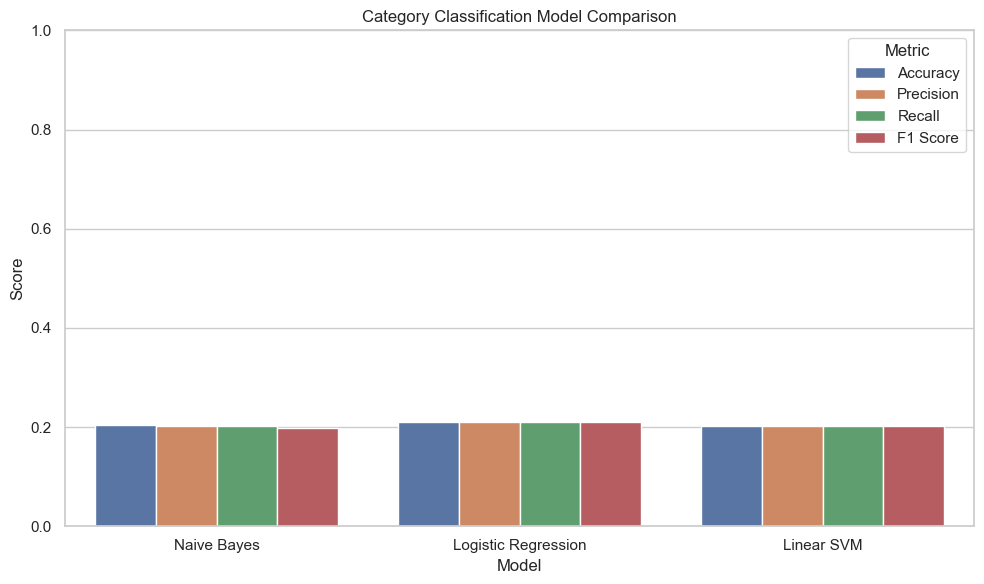

In [263]:
plt.figure(figsize=(10, 6))

category_plot = category_results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=category_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Category Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

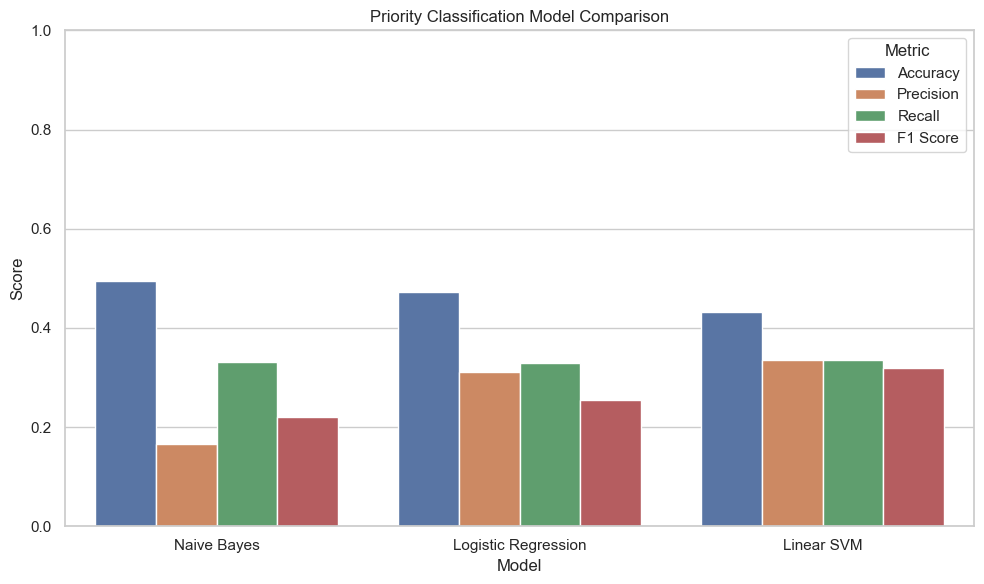

In [264]:
plt.figure(figsize=(10, 6))

priority_plot = priority_results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=priority_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Priority Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [265]:
best_category_row = category_results_df.loc[
    category_results_df["F1 Score"].idxmax()
]

best_category_model_name = best_category_row["Model"]

print("Best Category Model:", best_category_model_name)
print("Macro F1 Score:", round(best_category_row["F1 Score"], 4))

Best Category Model: Logistic Regression
Macro F1 Score: 0.2094


In [266]:
best_priority_row = priority_results_df.loc[
    priority_results_df["F1 Score"].idxmax()
]

best_priority_model_name = best_priority_row["Model"]

print("Best Priority Model:", best_priority_model_name)
print("Macro F1 Score:", round(best_priority_row["F1 Score"], 4))

Best Priority Model: Linear SVM
Macro F1 Score: 0.3191


In [267]:
category_models = {
    "Naive Bayes": nb_category,
    "Logistic Regression": lr_category,
    "Linear SVM": svm_category
}

priority_models = {
    "Naive Bayes": nb_priority,
    "Logistic Regression": lr_priority,
    "Linear SVM": svm_priority
}

In [268]:
best_category_model = category_models[best_category_model_name]
best_priority_model = priority_models[best_priority_model_name]

<h2>Stage 3 (Model improvements)</h2>

In [269]:
import warnings
warnings.filterwarnings("ignore")

from scipy.sparse import hstack, csr_matrix

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

In [270]:
print("CATEGORY MODEL RESULTS")
display(category_results_df.sort_values("F1 Score", ascending=False))

print("\nPRIORITY MODEL RESULTS")
display(priority_results_df.sort_values("F1 Score", ascending=False))

CATEGORY MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
1,Logistic Regression,0.209563,0.209556,0.209429,0.209379
2,Linear SVM,0.201299,0.201650,0.201465,0.201530
0,Naive Bayes,0.204250,0.203108,0.202618,0.199038



PRIORITY MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
2,Linear SVM,0.431523,0.336149,0.336048,0.319121
1,Logistic Regression,0.472845,0.310910,0.328475,0.254713
0,Naive Bayes,0.495277,0.165483,0.331752,0.220819


In [271]:
print("Best Category Model from Stage 2:")
print(best_category_model_name)

print("\nBest Priority Model from Stage 2:")
print(best_priority_model_name)

Best Category Model from Stage 2:
Logistic Regression

Best Priority Model from Stage 2:
Linear SVM


In [272]:
word_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=20000,
    sublinear_tf=True
)

X_train_word = word_tfidf.fit_transform(X_train_cat)
X_test_word = word_tfidf.transform(X_test_cat)

print("Word TF-IDF training shape:", X_train_word.shape)
print("Word TF-IDF testing shape :", X_test_word.shape)

Word TF-IDF training shape: (6775, 8552)
Word TF-IDF testing shape : (1694, 8552)


In [273]:
char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=30000,
    sublinear_tf=True
)

X_train_char = char_tfidf.fit_transform(X_train_cat)
X_test_char = char_tfidf.transform(X_test_cat)

print("Character TF-IDF training shape:", X_train_char.shape)
print("Character TF-IDF testing shape :", X_test_char.shape)

Character TF-IDF training shape: (6775, 17971)
Character TF-IDF testing shape : (1694, 17971)


In [274]:
X_train_combined = hstack([
    X_train_word,
    X_train_char
]).tocsr()

X_test_combined = hstack([
    X_test_word,
    X_test_char
]).tocsr()

print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape :", X_test_combined.shape)

Combined training shape: (6775, 26523)
Combined testing shape : (1694, 26523)


In [275]:
svm_results = []

C_values = [0.5, 1, 2, 5]

for C in C_values:

    model = LinearSVC(
        C=C,
        random_state=42
    )

    model.fit(X_train_combined, y_train_cat)

    predictions = model.predict(X_test_combined)

    svm_results.append({
        "C": C,
        "Accuracy": accuracy_score(y_test_cat, predictions),
        "Precision": precision_score(
            y_test_cat,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_cat,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_cat,
            predictions,
            average="macro",
            zero_division=0
        )
    })

svm_tuning_results = pd.DataFrame(svm_results)

display(
    svm_tuning_results.sort_values(
        "F1 Score",
        ascending=False
    )
)

,C,Accuracy,Precision,Recall,F1 Score
3,5.0,0.204250,0.203913,0.203887,0.203817
0,0.5,0.200708,0.200564,0.200592,0.200455
1,1.0,0.197757,0.197709,0.197622,0.197594
2,2.0,0.193034,0.192891,0.192796,0.192756


In [276]:
best_svm_row = svm_tuning_results.loc[
    svm_tuning_results["F1 Score"].idxmax()
]

best_svm_C = best_svm_row["C"]

print("Best SVM C:", best_svm_C)
print("Best SVM Macro F1:", best_svm_row["F1 Score"])

Best SVM C: 5.0
Best SVM Macro F1: 0.20381742095967365


In [277]:
enhanced_svm_category = LinearSVC(
    C=best_svm_C,
    random_state=42
)

enhanced_svm_category.fit(
    X_train_combined,
    y_train_cat
)

y_pred_enhanced_svm_cat = enhanced_svm_category.predict(
    X_test_combined
)

In [278]:
lr_results = []

C_values = [0.5, 1, 2, 5]

for C in C_values:

    model = LogisticRegression(
        C=C,
        max_iter=3000,
        random_state=42
    )

    model.fit(
        X_train_combined,
        y_train_cat
    )

    predictions = model.predict(
        X_test_combined
    )

    lr_results.append({
        "C": C,
        "Accuracy": accuracy_score(
            y_test_cat,
            predictions
        ),
        "Precision": precision_score(
            y_test_cat,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_cat,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_cat,
            predictions,
            average="macro",
            zero_division=0
        )
    })

lr_tuning_results = pd.DataFrame(lr_results)

display(
    lr_tuning_results.sort_values(
        "F1 Score",
        ascending=False
    )
)

,C,Accuracy,Precision,Recall,F1 Score
0,0.5,0.206612,0.206220,0.206248,0.206120
1,1.0,0.202479,0.202184,0.202142,0.202079
3,5.0,0.201889,0.201827,0.201788,0.201760
2,2.0,0.200708,0.200553,0.200551,0.200509


In [279]:
best_lr_row = lr_tuning_results.loc[
    lr_tuning_results["F1 Score"].idxmax()
]

best_lr_C = best_lr_row["C"]

print("Best Logistic Regression C:", best_lr_C)
print("Best Logistic Regression Macro F1:", best_lr_row["F1 Score"])

Best Logistic Regression C: 0.5
Best Logistic Regression Macro F1: 0.20612029818918676


In [280]:
enhanced_lr_category = LogisticRegression(
    C=best_lr_C,
    max_iter=3000,
    random_state=42
)

enhanced_lr_category.fit(
    X_train_combined,
    y_train_cat
)

y_pred_enhanced_lr_cat = enhanced_lr_category.predict(
    X_test_combined
)

In [281]:
stage3_category_results = []

stage3_category_results.append(
    evaluate_model(
        "Stage 2 - Naive Bayes",
        y_test_cat,
        y_pred_nb_cat
    )
)

stage3_category_results.append(
    evaluate_model(
        "Stage 2 - Logistic Regression",
        y_test_cat,
        y_pred_lr_cat
    )
)

stage3_category_results.append(
    evaluate_model(
        "Stage 2 - Linear SVM",
        y_test_cat,
        y_pred_svm_cat
    )
)

stage3_category_results.append(
    evaluate_model(
        "Stage 3 - Enhanced SVM",
        y_test_cat,
        y_pred_enhanced_svm_cat
    )
)

stage3_category_results.append(
    evaluate_model(
        "Stage 3 - Enhanced Logistic Regression",
        y_test_cat,
        y_pred_enhanced_lr_cat
    )
)

stage3_category_results_df = pd.DataFrame(
    stage3_category_results
)

display(
    stage3_category_results_df.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Stage 2 - Logistic Regression,0.209563,0.209556,0.209429,0.209379
4,Stage 3 - Enhanced Logistic Regression,0.206612,0.206220,0.206248,0.206120
3,Stage 3 - Enhanced SVM,0.204250,0.203913,0.203887,0.203817
2,Stage 2 - Linear SVM,0.201299,0.201650,0.201465,0.201530
0,Stage 2 - Naive Bayes,0.204250,0.203108,0.202618,0.199038


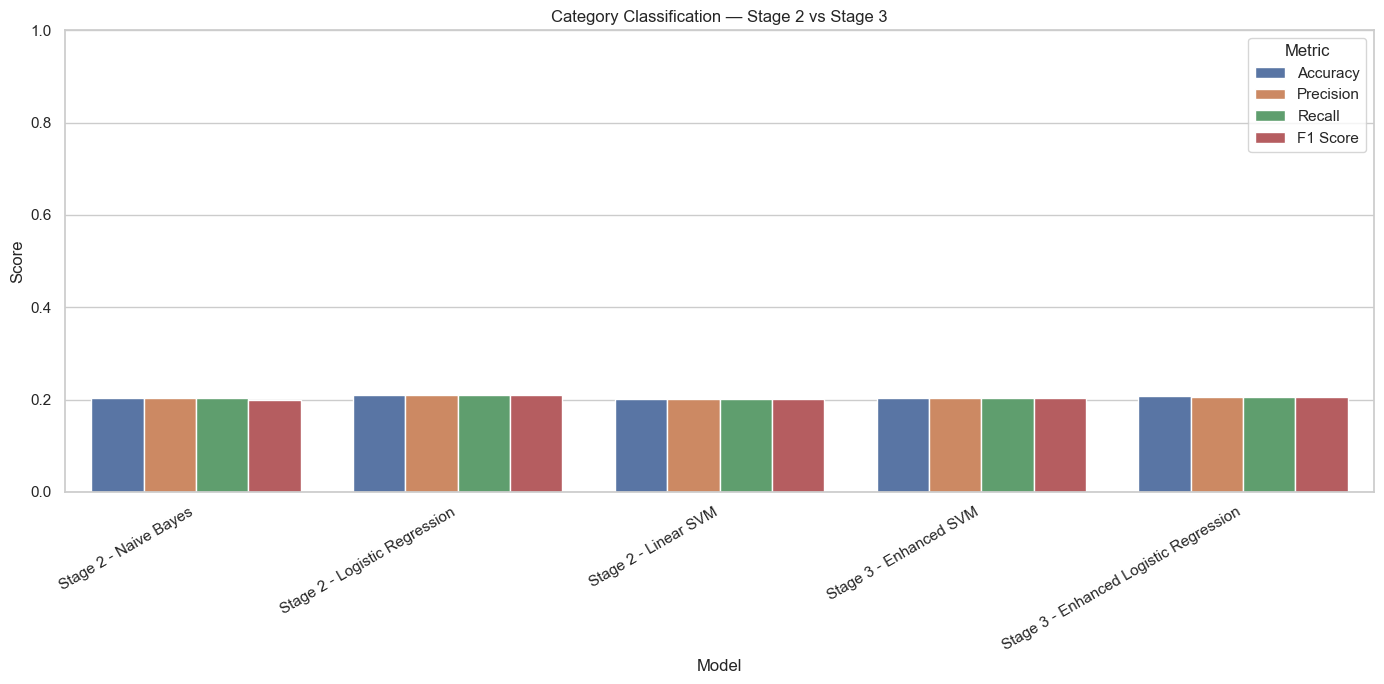

In [282]:
category_plot_df = stage3_category_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=category_plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Category Classification — Stage 2 vs Stage 3")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [283]:
best_category_stage3_row = stage3_category_results_df.loc[
    stage3_category_results_df["F1 Score"].idxmax()
]

best_category_stage3_name = best_category_stage3_row["Model"]

print("Best Category Model:")
print(best_category_stage3_name)

Best Category Model:
Stage 2 - Logistic Regression


In [284]:
if best_category_stage3_name == "Stage 3 - Enhanced SVM":
    best_category_predictions = y_pred_enhanced_svm_cat
    best_category_final_model = enhanced_svm_category

elif best_category_stage3_name == "Stage 3 - Enhanced Logistic Regression":
    best_category_predictions = y_pred_enhanced_lr_cat
    best_category_final_model = enhanced_lr_category

elif best_category_stage3_name == "Stage 2 - Logistic Regression":
    best_category_predictions = y_pred_lr_cat
    best_category_final_model = lr_category

elif best_category_stage3_name == "Stage 2 - Linear SVM":
    best_category_predictions = y_pred_svm_cat
    best_category_final_model = svm_category

else:
    best_category_predictions = y_pred_nb_cat
    best_category_final_model = nb_category

In [285]:
print(
    classification_report(
        y_test_cat,
        best_category_predictions,
        zero_division=0
    )
)

                      precision    recall  f1-score   support

     Billing inquiry       0.22      0.21      0.22       327
Cancellation request       0.20      0.19      0.20       339
     Product inquiry       0.21      0.20      0.20       328
      Refund request       0.17      0.18      0.18       351
     Technical issue       0.24      0.26      0.25       349

            accuracy                           0.21      1694
           macro avg       0.21      0.21      0.21      1694
        weighted avg       0.21      0.21      0.21      1694



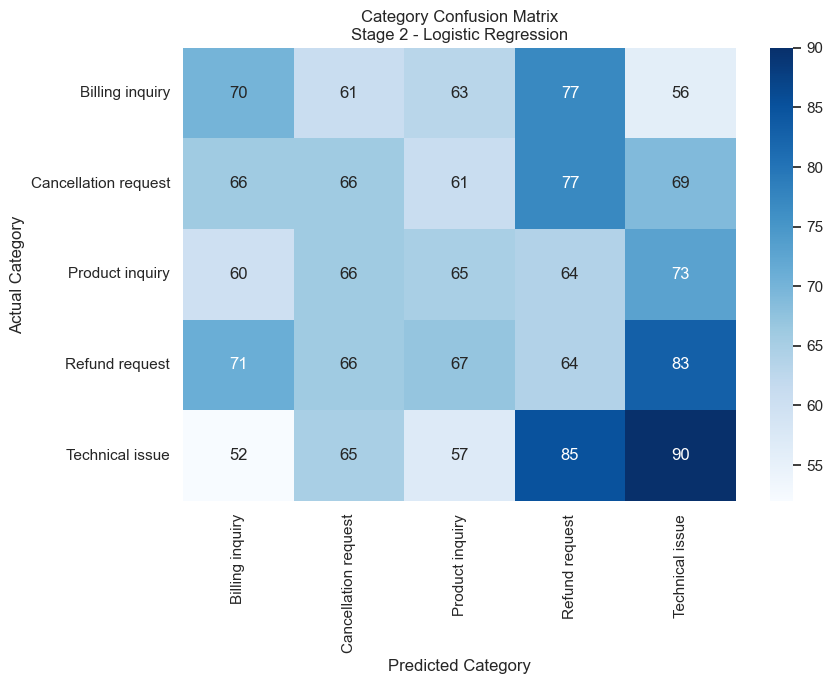

In [286]:
category_cm = confusion_matrix(
    y_test_cat,
    best_category_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    category_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y_test_cat.unique()),
    yticklabels=sorted(y_test_cat.unique())
)

plt.title(
    f"Category Confusion Matrix\n{best_category_stage3_name}"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [287]:
priority_word_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=20000,
    sublinear_tf=True
)

X_train_pri_word = priority_word_tfidf.fit_transform(
    X_train_pri
)

X_test_pri_word = priority_word_tfidf.transform(
    X_test_pri
)

print(
    "Priority word TF-IDF training shape:",
    X_train_pri_word.shape
)

Priority word TF-IDF training shape: (6775, 8584)


In [288]:
priority_char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=30000,
    sublinear_tf=True
)

X_train_pri_char = priority_char_tfidf.fit_transform(
    X_train_pri
)

X_test_pri_char = priority_char_tfidf.transform(
    X_test_pri
)

In [289]:
X_train_pri_combined = hstack([
    X_train_pri_word,
    X_train_pri_char
]).tocsr()

X_test_pri_combined = hstack([
    X_test_pri_word,
    X_test_pri_char
]).tocsr()

print(
    "Combined priority training shape:",
    X_train_pri_combined.shape
)

Combined priority training shape: (6775, 26485)


In [290]:
priority_svm_results = []

C_values = [0.5, 1, 2, 5]

for C in C_values:

    model = LinearSVC(
        C=C,
        random_state=42
    )

    model.fit(
        X_train_pri_combined,
        y_train_pri
    )

    predictions = model.predict(
        X_test_pri_combined
    )

    priority_svm_results.append({
        "C": C,
        "Accuracy": accuracy_score(
            y_test_pri,
            predictions
        ),
        "Precision": precision_score(
            y_test_pri,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_pri,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_pri,
            predictions,
            average="macro",
            zero_division=0
        )
    })

priority_svm_tuning = pd.DataFrame(
    priority_svm_results
)

display(
    priority_svm_tuning.sort_values(
        "F1 Score",
        ascending=False
    )
)

,C,Accuracy,Precision,Recall,F1 Score
3,5.0,0.400236,0.339952,0.339370,0.337295
2,2.0,0.404959,0.332648,0.333297,0.327899
0,0.5,0.436836,0.339874,0.337687,0.318346
1,1.0,0.417355,0.326837,0.330169,0.317292


In [291]:
best_priority_svm_row = priority_svm_tuning.loc[
    priority_svm_tuning["F1 Score"].idxmax()
]

best_priority_svm_C = best_priority_svm_row["C"]

print("Best Priority SVM C:", best_priority_svm_C)

Best Priority SVM C: 5.0


In [292]:
enhanced_svm_priority = LinearSVC(
    C=best_priority_svm_C,
    random_state=42
)

enhanced_svm_priority.fit(
    X_train_pri_combined,
    y_train_pri
)

y_pred_enhanced_svm_pri = enhanced_svm_priority.predict(
    X_test_pri_combined
)

In [293]:
priority_lr_results = []

C_values = [0.5, 1, 2, 5]

for C in C_values:

    model = LogisticRegression(
        C=C,
        max_iter=3000,
        random_state=42
    )

    model.fit(
        X_train_pri_combined,
        y_train_pri
    )

    predictions = model.predict(
        X_test_pri_combined
    )

    priority_lr_results.append({
        "C": C,
        "Accuracy": accuracy_score(
            y_test_pri,
            predictions
        ),
        "Precision": precision_score(
            y_test_pri,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_pri,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_pri,
            predictions,
            average="macro",
            zero_division=0
        )
    })

priority_lr_tuning = pd.DataFrame(
    priority_lr_results
)

display(
    priority_lr_tuning.sort_values(
        "F1 Score",
        ascending=False
    )
)

,C,Accuracy,Precision,Recall,F1 Score
3,5.0,0.417355,0.326107,0.328844,0.315349
2,2.0,0.448642,0.344780,0.340062,0.313919
1,1.0,0.466352,0.334197,0.337567,0.290119
0,0.5,0.475207,0.305436,0.328868,0.251969


In [294]:
best_priority_lr_row = priority_lr_tuning.loc[
    priority_lr_tuning["F1 Score"].idxmax()
]

best_priority_lr_C = best_priority_lr_row["C"]

print(
    "Best Priority Logistic Regression C:",
    best_priority_lr_C
)

Best Priority Logistic Regression C: 5.0


In [295]:
enhanced_lr_priority = LogisticRegression(
    C=best_priority_lr_C,
    max_iter=3000,
    random_state=42
)

enhanced_lr_priority.fit(
    X_train_pri_combined,
    y_train_pri
)

y_pred_enhanced_lr_pri = enhanced_lr_priority.predict(
    X_test_pri_combined
)

In [296]:
stage3_priority_results = []

stage3_priority_results.append(
    evaluate_model(
        "Stage 2 - Naive Bayes",
        y_test_pri,
        y_pred_nb_pri
    )
)

stage3_priority_results.append(
    evaluate_model(
        "Stage 2 - Logistic Regression",
        y_test_pri,
        y_pred_lr_pri
    )
)

stage3_priority_results.append(
    evaluate_model(
        "Stage 2 - Linear SVM",
        y_test_pri,
        y_pred_svm_pri
    )
)

stage3_priority_results.append(
    evaluate_model(
        "Stage 3 - Enhanced SVM",
        y_test_pri,
        y_pred_enhanced_svm_pri
    )
)

stage3_priority_results.append(
    evaluate_model(
        "Stage 3 - Enhanced Logistic Regression",
        y_test_pri,
        y_pred_enhanced_lr_pri
    )
)

stage3_priority_results_df = pd.DataFrame(
    stage3_priority_results
)

display(
    stage3_priority_results_df.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
3,Stage 3 - Enhanced SVM,0.400236,0.339952,0.339370,0.337295
2,Stage 2 - Linear SVM,0.431523,0.336149,0.336048,0.319121
4,Stage 3 - Enhanced Logistic Regression,0.417355,0.326107,0.328844,0.315349
1,Stage 2 - Logistic Regression,0.472845,0.310910,0.328475,0.254713
0,Stage 2 - Naive Bayes,0.495277,0.165483,0.331752,0.220819


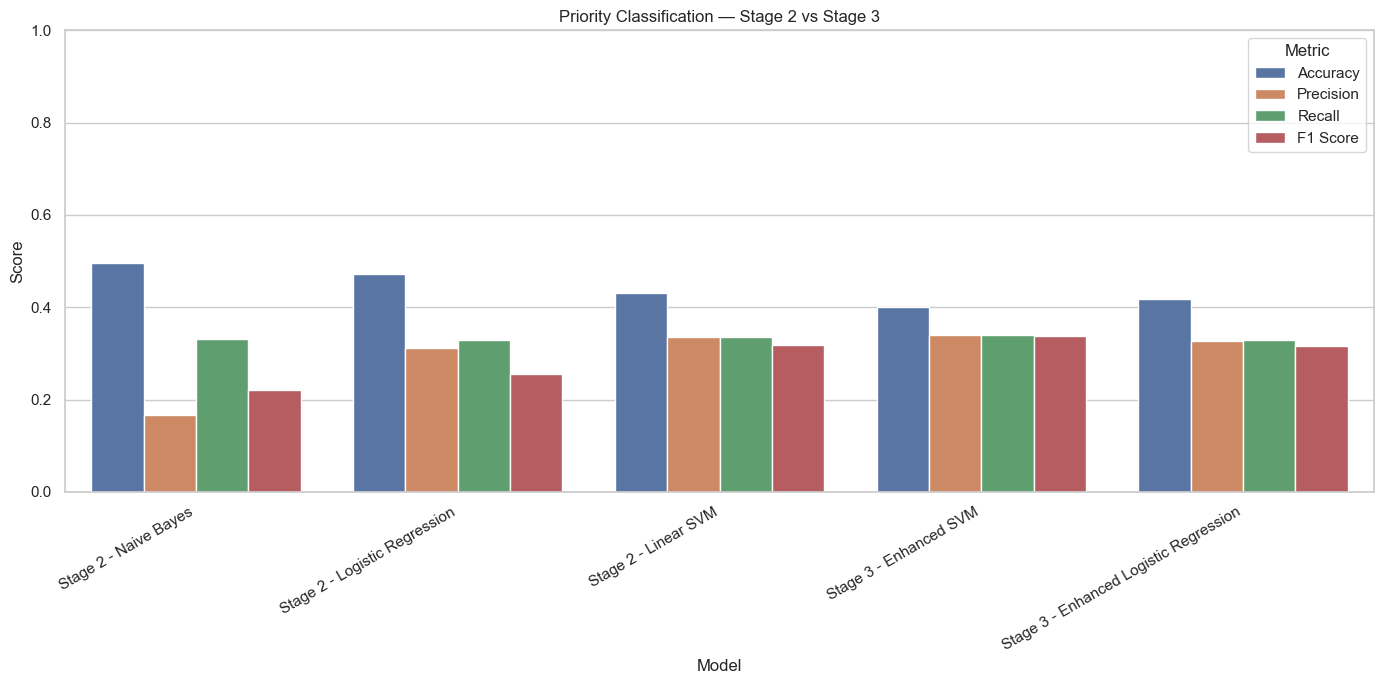

In [297]:
priority_plot_df = stage3_priority_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=priority_plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Priority Classification — Stage 2 vs Stage 3")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [298]:
best_priority_stage3_row = stage3_priority_results_df.loc[
    stage3_priority_results_df["F1 Score"].idxmax()
]

best_priority_stage3_name = best_priority_stage3_row["Model"]

print("Best Priority Model:")
print(best_priority_stage3_name)

Best Priority Model:
Stage 3 - Enhanced SVM


In [299]:
if best_priority_stage3_name == "Stage 3 - Enhanced SVM":

    best_priority_predictions = y_pred_enhanced_svm_pri

    best_priority_final_model = enhanced_svm_priority

elif best_priority_stage3_name == "Stage 3 - Enhanced Logistic Regression":

    best_priority_predictions = y_pred_enhanced_lr_pri

    best_priority_final_model = enhanced_lr_priority

elif best_priority_stage3_name == "Stage 2 - Logistic Regression":

    best_priority_predictions = y_pred_lr_pri

    best_priority_final_model = lr_priority

elif best_priority_stage3_name == "Stage 2 - Linear SVM":

    best_priority_predictions = y_pred_svm_pri

    best_priority_final_model = svm_priority

else:

    best_priority_predictions = y_pred_nb_pri

    best_priority_final_model = nb_priority

In [300]:
print(
    classification_report(
        y_test_pri,
        best_priority_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

        High       0.50      0.58      0.54       843
         Low       0.23      0.19      0.21       413
      Medium       0.29      0.24      0.26       438

    accuracy                           0.40      1694
   macro avg       0.34      0.34      0.34      1694
weighted avg       0.38      0.40      0.39      1694



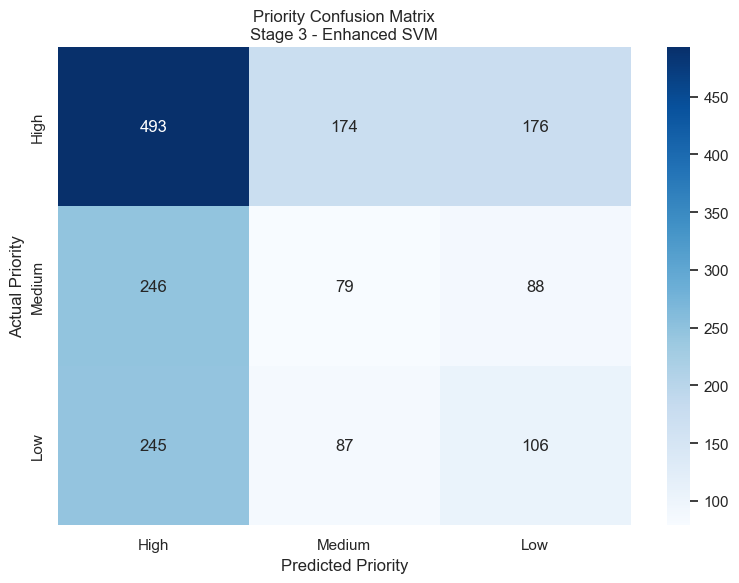

In [301]:
priority_cm = confusion_matrix(
    y_test_pri,
    best_priority_predictions
)

priority_labels = ["High", "Medium", "Low"]

plt.figure(figsize=(8, 6))

sns.heatmap(
    priority_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=priority_labels,
    yticklabels=priority_labels
)

plt.title(
    f"Priority Confusion Matrix\n{best_priority_stage3_name}"
)

plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")

plt.tight_layout()
plt.show()

In [302]:
category_report = classification_report(
    y_test_cat,
    best_category_predictions,
    output_dict=True,
    zero_division=0
)

category_report_df = pd.DataFrame(
    category_report
).transpose()

display(category_report_df)

,precision,recall,f1-score,support
Billing inquiry,0.219436,0.214067,0.216718,327.000000
Cancellation request,0.203704,0.194690,0.199095,339.000000
Product inquiry,0.207668,0.198171,0.202808,328.000000
Refund request,0.174387,0.182336,0.178273,351.000000
Technical issue,0.242588,0.257880,0.250000,349.000000
accuracy,0.209563,0.209563,0.209563,0.209563
macro avg,0.209556,0.209429,0.209379,1694.000000
weighted avg,0.209444,0.209563,0.209389,1694.000000


In [303]:
priority_report = classification_report(
    y_test_pri,
    best_priority_predictions,
    output_dict=True,
    zero_division=0
)

priority_report_df = pd.DataFrame(
    priority_report
).transpose()

display(priority_report_df)

,precision,recall,f1-score,support
High,0.501016,0.584816,0.539683,843.000000
Low,0.232353,0.191283,0.209827,413.000000
Medium,0.286486,0.242009,0.262376,438.000000
accuracy,0.400236,0.400236,0.400236,0.400236
macro avg,0.339952,0.339370,0.337295,1694.000000
weighted avg,0.380047,0.400236,0.387563,1694.000000


In [304]:
category_test_results = pd.DataFrame({
    "Text": X_test_cat.values,
    "Actual": y_test_cat.values,
    "Predicted": best_category_predictions
})

category_errors = category_test_results[
    category_test_results["Actual"] !=
    category_test_results["Predicted"]
].copy()

print(
    "Number of incorrect category predictions:",
    len(category_errors)
)

print(
    "Category error rate:",
    round(
        len(category_errors) / len(category_test_results) * 100,
        2
    ),
    "%"
)

display(
    category_errors.head(20)
)

Number of incorrect category predictions: 1339
Category error rate: 79.04 %


,Text,Actual,Predicted
0,installation support im issue productpurchased please assist problem started occurring recent software update havent made changes device,Product inquiry,Cancellation request
1,refund request im issue productpurchased please assist ive recently updated firmware productpurchased issue started happening afterward could related update,Refund request,Cancellation request
2,cancellation request im issue productpurchased please assist problem started occurring recent software update havent made changes device,Billing inquiry,Cancellation request
3,account access im issue productpurchased please assist productnames product name contains product identifier use verify validity certain products products valid ive noticed sudden decrease battery...,Product inquiry,Billing inquiry
4,cancellation request im issue productpurchased please assist careful making choices customers different providers needs wants offer tools make im using original charger came productpurchased charg...,Refund request,Cancellation request
5,peripheral compatibility im issue productpurchased please assist using alternative solution first thing need create event product item update old one ive tried troubleshooting steps mentioned user...,Cancellation request,Technical issue
6,refund request im issue productpurchased please assist cant anything want product sold thats expensive transaction ive got something problem started occurring recent software update havent made ch...,Technical issue,Cancellation request
7,network problem im issue productpurchased please assist please select valid product email lists subscribe email href im concerned security productpurchased would like ensure data safe,Technical issue,Product inquiry
8,delivery problem im facing issues logging productpurchased account says account locked unlock please go ahead ask aware account automatically get locked ive performed factory reset productpurchase...,Refund request,Billing inquiry
11,data loss productpurchased making strange noises functioning properly suspect might hardware issue please help ive checked available software updates productpurchased none,Technical issue,Refund request


In [305]:
category_confusion_pairs = (
    category_errors
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(category_confusion_pairs.head(15))

,Actual,Predicted,Count
19,Technical issue,Refund request,85
15,Refund request,Technical issue,83
2,Billing inquiry,Refund request,77
6,Cancellation request,Refund request,77
11,Product inquiry,Technical issue,73
12,Refund request,Billing inquiry,71
7,Cancellation request,Technical issue,69
14,Refund request,Product inquiry,67
13,Refund request,Cancellation request,66
9,Product inquiry,Cancellation request,66


In [306]:
priority_test_results = pd.DataFrame({
    "Text": X_test_pri.values,
    "Actual": y_test_pri.values,
    "Predicted": best_priority_predictions
})

priority_errors = priority_test_results[
    priority_test_results["Actual"] !=
    priority_test_results["Predicted"]
].copy()

print(
    "Number of incorrect priority predictions:",
    len(priority_errors)
)

print(
    "Priority error rate:",
    round(
        len(priority_errors) / len(priority_test_results) * 100,
        2
    ),
    "%"
)

display(
    priority_errors.head(20)
)

Number of incorrect priority predictions: 1016
Priority error rate: 59.98 %


,Text,Actual,Predicted
1,hardware issue im issue productpurchased please assist product purchased ive followed troubleshooting steps mentioned user manual issue persists,Low,High
3,delivery problem im issue productpurchased please assist told product always two options dont product ive checked device settings made sure everything configured correctly,High,Medium
5,cancellation request im issue productpurchased please assist im issue productpurchased please assist problem last two files problem issue im facing intermittent sometimes works fine times acts une...,Low,Medium
9,product setup ive noticed software bug productpurchased app causing data loss unexpected errors resolve issue windows means using command line utility getwmiobject ive already contacted customer s...,High,Low
10,product compatibility im issue productpurchased please assist first thing catch attention define productpurchased first line breaks line ive already contacted customer support multiple times issue...,Medium,High
12,account access im trouble connecting productpurchased home wifi network doesnt detect networks although devices connecting fine done resolve issue use existing router ive noticed peculiar error me...,High,Low
14,peripheral compatibility im issue productpurchased please assist error guess especially since single successful refund last three days thanks k im concerned security productpurchased would like en...,High,Low
16,data loss im issue productpurchased please assist thank im issue productp ive checked device settings made sure everything configured correctly,Low,High
17,delivery problem im issue productpurchased please assist need time could help update version issue im facing intermittent sometimes works fine times acts unexpectedly,Medium,High
19,data loss im issue productpurchased please assist use promo code get neweggcom every subsequent purchase ive already contacted customer support multiple times issue remains unresolved,Low,High


In [307]:
priority_confusion_pairs = (
    priority_errors
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(priority_confusion_pairs)

,Actual,Predicted,Count
2,Low,High,246
4,Medium,High,245
1,High,Medium,176
0,High,Low,174
3,Low,Medium,88
5,Medium,Low,87


In [308]:
metadata_columns = [
    "Customer Age",
    "Customer Gender",
    "Product Purchased",
    "Ticket Channel"
]

metadata = df[metadata_columns].copy()

display(metadata.head())

,Customer Age,Customer Gender,Product Purchased,Ticket Channel
0,32,Other,GoPro Hero,Social media
1,42,Female,LG Smart TV,Chat
2,48,Other,Dell XPS,Social media
3,27,Female,Microsoft Office,Social media
4,67,Female,Autodesk AutoCAD,Email


In [309]:
metadata.isnull().sum()

Customer Age         0
Customer Gender      0
Product Purchased    0
Ticket Channel       0
dtype: int64

In [310]:

train_cat_indices = X_train_cat.index
test_cat_indices = X_test_cat.index

metadata_train_cat = metadata.loc[
    train_cat_indices
].copy()

metadata_test_cat = metadata.loc[
    test_cat_indices
].copy()

print(
    "Metadata training shape:",
    metadata_train_cat.shape
)

print(
    "Metadata testing shape:",
    metadata_test_cat.shape
)

Metadata training shape: (6775, 4)
Metadata testing shape: (1694, 4)


In [311]:
categorical_columns = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Channel"
]

encoder = OneHotEncoder(
    handle_unknown="ignore"
)

train_cat_encoded = encoder.fit_transform(
    metadata_train_cat[categorical_columns]
)

test_cat_encoded = encoder.transform(
    metadata_test_cat[categorical_columns]
)

print(
    "Encoded metadata shape:",
    train_cat_encoded.shape
)

Encoded metadata shape: (6775, 49)


In [312]:
age_scaler = StandardScaler()

train_age = age_scaler.fit_transform(
    metadata_train_cat[["Customer Age"]]
)

test_age = age_scaler.transform(
    metadata_test_cat[["Customer Age"]]
)

train_age_sparse = csr_matrix(train_age)
test_age_sparse = csr_matrix(test_age)

In [313]:
X_train_cat_final = hstack([
    X_train_combined,
    train_cat_encoded,
    train_age_sparse
]).tocsr()

X_test_cat_final = hstack([
    X_test_combined,
    test_cat_encoded,
    test_age_sparse
]).tocsr()

print(
    "Final training feature shape:",
    X_train_cat_final.shape
)

print(
    "Final testing feature shape:",
    X_test_cat_final.shape
)

Final training feature shape: (6775, 26573)
Final testing feature shape: (1694, 26573)


In [314]:
metadata_svm = LinearSVC(
    C=best_svm_C,
    random_state=42
)

metadata_svm.fit(
    X_train_cat_final,
    y_train_cat
)

y_pred_metadata_svm_cat = metadata_svm.predict(
    X_test_cat_final
)

In [315]:
metadata_category_result = evaluate_model(
    "Stage 3 - Text + Metadata SVM",
    y_test_cat,
    y_pred_metadata_svm_cat
)

display(
    pd.DataFrame([metadata_category_result])
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3 - Text + Metadata SVM,0.195986,0.196164,0.195875,0.195969


In [316]:
category_final_comparison = pd.concat([
    stage3_category_results_df,
    pd.DataFrame([metadata_category_result])
], ignore_index=True)

display(
    category_final_comparison.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Stage 2 - Logistic Regression,0.209563,0.209556,0.209429,0.209379
4,Stage 3 - Enhanced Logistic Regression,0.206612,0.206220,0.206248,0.206120
3,Stage 3 - Enhanced SVM,0.204250,0.203913,0.203887,0.203817
2,Stage 2 - Linear SVM,0.201299,0.201650,0.201465,0.201530
0,Stage 2 - Naive Bayes,0.204250,0.203108,0.202618,0.199038
5,Stage 3 - Text + Metadata SVM,0.195986,0.196164,0.195875,0.195969


In [317]:
best_category_final_row = category_final_comparison.loc[
    category_final_comparison["F1 Score"].idxmax()
]

best_category_final_name = (
    best_category_final_row["Model"]
)

best_category_final_f1 = (
    best_category_final_row["F1 Score"]
)

print("FINAL CATEGORY MODEL")

print("Model:", best_category_final_name)
print(
    "Accuracy:",
    round(
        best_category_final_row["Accuracy"],
        4
    )
)

print(
    "Macro F1:",
    round(
        best_category_final_f1,
        4
    )
)

FINAL CATEGORY MODEL
Model: Stage 2 - Logistic Regression
Accuracy: 0.2096
Macro F1: 0.2094


In [318]:
train_pri_indices = X_train_pri.index
test_pri_indices = X_test_pri.index

metadata_train_pri = metadata.loc[
    train_pri_indices
].copy()

metadata_test_pri = metadata.loc[
    test_pri_indices
].copy()

In [319]:
priority_encoder = OneHotEncoder(
    handle_unknown="ignore"
)

train_pri_encoded = priority_encoder.fit_transform(
    metadata_train_pri[categorical_columns]
)

test_pri_encoded = priority_encoder.transform(
    metadata_test_pri[categorical_columns]
)

In [320]:
priority_age_scaler = StandardScaler()

train_pri_age = priority_age_scaler.fit_transform(
    metadata_train_pri[["Customer Age"]]
)

test_pri_age = priority_age_scaler.transform(
    metadata_test_pri[["Customer Age"]]
)

train_pri_age_sparse = csr_matrix(train_pri_age)
test_pri_age_sparse = csr_matrix(test_pri_age)

In [321]:
X_train_pri_final = hstack([
    X_train_pri_combined,
    train_pri_encoded,
    train_pri_age_sparse
]).tocsr()

X_test_pri_final = hstack([
    X_test_pri_combined,
    test_pri_encoded,
    test_pri_age_sparse
]).tocsr()

In [322]:
metadata_svm_priority = LinearSVC(
    C=best_priority_svm_C,
    random_state=42
)

metadata_svm_priority.fit(
    X_train_pri_final,
    y_train_pri
)

y_pred_metadata_svm_pri = (
    metadata_svm_priority.predict(
        X_test_pri_final
    )
)

In [323]:
metadata_priority_result = evaluate_model(
    "Stage 3 - Text + Metadata SVM",
    y_test_pri,
    y_pred_metadata_svm_pri
)

display(
    pd.DataFrame([metadata_priority_result])
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3 - Text + Metadata SVM,0.402597,0.342024,0.341728,0.339694


In [324]:
priority_final_comparison = pd.concat([
    stage3_priority_results_df,
    pd.DataFrame([metadata_priority_result])
], ignore_index=True)

display(
    priority_final_comparison.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
5,Stage 3 - Text + Metadata SVM,0.402597,0.342024,0.341728,0.339694
3,Stage 3 - Enhanced SVM,0.400236,0.339952,0.339370,0.337295
2,Stage 2 - Linear SVM,0.431523,0.336149,0.336048,0.319121
4,Stage 3 - Enhanced Logistic Regression,0.417355,0.326107,0.328844,0.315349
1,Stage 2 - Logistic Regression,0.472845,0.310910,0.328475,0.254713
0,Stage 2 - Naive Bayes,0.495277,0.165483,0.331752,0.220819


In [325]:
best_priority_final_row = priority_final_comparison.loc[
    priority_final_comparison["F1 Score"].idxmax()
]

best_priority_final_name = (
    best_priority_final_row["Model"]
)

print("FINAL PRIORITY MODEL")

print("Model:", best_priority_final_name)

print(
    "Accuracy:",
    round(
        best_priority_final_row["Accuracy"],
        4
    )
)

print(
    "Macro F1:",
    round(
        best_priority_final_row["F1 Score"],
        4
    )
)

FINAL PRIORITY MODEL
Model: Stage 3 - Text + Metadata SVM
Accuracy: 0.4026
Macro F1: 0.3397


In [326]:
if best_category_final_name == "Stage 3 - Text + Metadata SVM":

    final_category_predictions = y_pred_metadata_svm_cat
    final_category_model = metadata_svm

else:

    final_category_predictions = best_category_predictions
    final_category_model = best_category_final_model

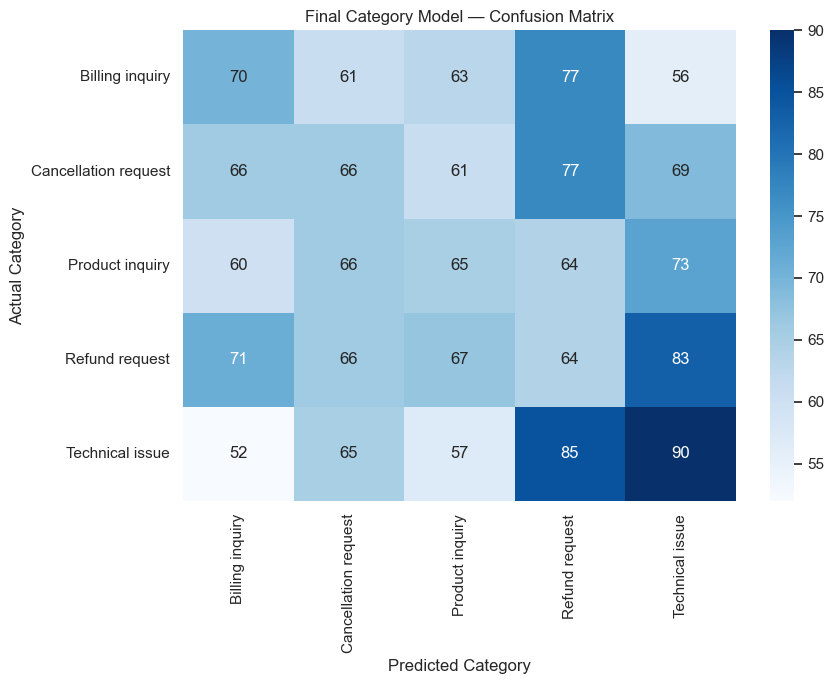

In [327]:
final_category_cm = confusion_matrix(
    y_test_cat,
    final_category_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    final_category_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y_test_cat.unique()),
    yticklabels=sorted(y_test_cat.unique())
)

plt.title("Final Category Model — Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [328]:
if best_priority_final_name == "Stage 3 - Text + Metadata SVM":

    final_priority_predictions = y_pred_metadata_svm_pri
    final_priority_model = metadata_svm_priority

else:

    final_priority_predictions = best_priority_predictions
    final_priority_model = best_priority_final_model

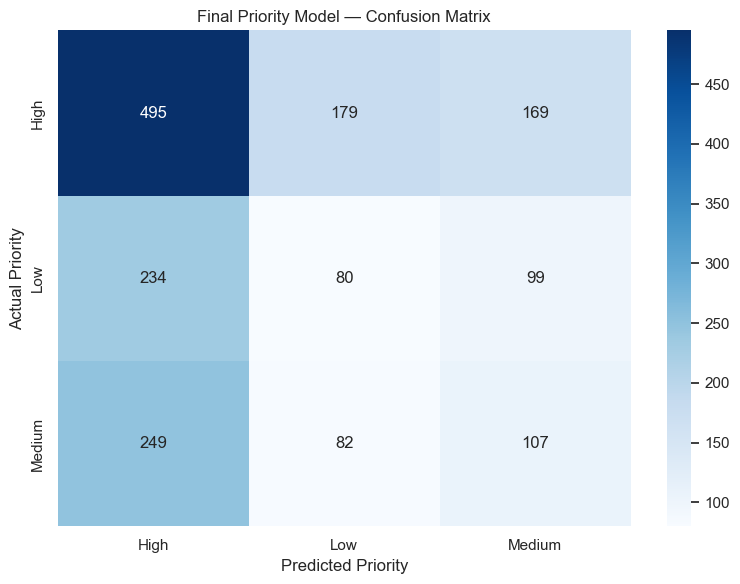

In [329]:
final_priority_cm = confusion_matrix(
    y_test_pri,
    final_priority_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    final_priority_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["High", "Low", "Medium"],
    yticklabels=["High", "Low", "Medium"]
)

plt.title("Final Priority Model — Confusion Matrix")
plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")

plt.tight_layout()
plt.show()

In [330]:
print("=" * 60)
print("STAGE 3 FINAL MODEL SUMMARY")
print("=" * 60)

print("\nCATEGORY CLASSIFICATION")
print("-" * 60)
print("Best Model:", best_category_final_name)
print(
    "Accuracy:",
    round(best_category_final_row["Accuracy"], 4)
)
print(
    "Macro Precision:",
    round(best_category_final_row["Precision"], 4)
)
print(
    "Macro Recall:",
    round(best_category_final_row["Recall"], 4)
)
print(
    "Macro F1:",
    round(best_category_final_row["F1 Score"], 4)
)

print("\nPRIORITY CLASSIFICATION")
print("-" * 60)
print("Best Model:", best_priority_final_name)
print(
    "Accuracy:",
    round(best_priority_final_row["Accuracy"], 4)
)
print(
    "Macro Precision:",
    round(best_priority_final_row["Precision"], 4)
)
print(
    "Macro Recall:",
    round(best_priority_final_row["Recall"], 4)
)
print(
    "Macro F1:",
    round(best_priority_final_row["F1 Score"], 4)
)

STAGE 3 FINAL MODEL SUMMARY

CATEGORY CLASSIFICATION
------------------------------------------------------------
Best Model: Stage 2 - Logistic Regression
Accuracy: 0.2096
Macro Precision: 0.2096
Macro Recall: 0.2094
Macro F1: 0.2094

PRIORITY CLASSIFICATION
------------------------------------------------------------
Best Model: Stage 3 - Text + Metadata SVM
Accuracy: 0.4026
Macro Precision: 0.342
Macro Recall: 0.3417
Macro F1: 0.3397


In [331]:

category_final_comparison.to_csv(
    "category_model_comparison.csv",
    index=False
)

priority_final_comparison.to_csv(
    "priority_model_comparison.csv",
    index=False
)

print("Stage 3 evaluation results saved successfully.")

Stage 3 evaluation results saved successfully.


In [332]:
df["Raw_Ticket_Text"] = (
    df["Ticket Subject"].fillna("")
    + " "
    + df["Ticket Description"].fillna("")
)

print("Raw text example:")
print(df["Raw_Ticket_Text"].iloc[0])

print("\nCleaned text example:")
print(df["Clean_Text"].iloc[0])

Raw text example:
Product setup I'm having an issue with the {product_purchased}. Please assist.

Your billing zip code is: 71701.

We appreciate that you have requested a website address.

Please double check your email address. I've tried troubleshooting steps mentioned in the user manual, but the issue persists.

Cleaned text example:
product setup im issue productpurchased please assist billing zip code appreciate requested website address please double check email address ive tried troubleshooting steps mentioned user manual issue persists


In [333]:

X_raw = df["Raw_Ticket_Text"]
y_category = df["Ticket Type"]

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

print("Training samples:", len(X_train_raw))
print("Testing samples :", len(X_test_raw))

Training samples: 6775
Testing samples : 1694


In [334]:
raw_word_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.98,
    max_features=30000,
    sublinear_tf=True
)

X_train_raw_tfidf = raw_word_tfidf.fit_transform(
    X_train_raw
)

X_test_raw_tfidf = raw_word_tfidf.transform(
    X_test_raw
)

print(
    "Raw TF-IDF training shape:",
    X_train_raw_tfidf.shape
)

Raw TF-IDF training shape: (6775, 25163)


In [335]:
raw_lr = LogisticRegression(
    C=2,
    max_iter=3000,
    random_state=42
)

raw_lr.fit(
    X_train_raw_tfidf,
    y_train_raw
)

y_pred_raw_lr = raw_lr.predict(
    X_test_raw_tfidf
)

raw_lr_result = evaluate_model(
    "Stage 3.5 - Raw Text Logistic Regression",
    y_test_raw,
    y_pred_raw_lr
)

display(
    pd.DataFrame([raw_lr_result])
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3.5 - Raw Text Logistic Regression,0.212515,0.211684,0.212094,0.2117


In [336]:
weighted_lr = LogisticRegression(
    C=2,
    class_weight="balanced",
    max_iter=3000,
    random_state=42
)

weighted_lr.fit(
    X_train_raw_tfidf,
    y_train_raw
)

y_pred_weighted_lr = weighted_lr.predict(
    X_test_raw_tfidf
)

weighted_lr_result = evaluate_model(
    "Stage 3.5 - Weighted Logistic Regression",
    y_test_raw,
    y_pred_weighted_lr
)

display(
    pd.DataFrame([weighted_lr_result])
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3.5 - Weighted Logistic Regression,0.206021,0.206357,0.206007,0.205805


In [337]:
weighted_svm = LinearSVC(
    C=1,
    class_weight="balanced",
    random_state=42
)

weighted_svm.fit(
    X_train_raw_tfidf,
    y_train_raw
)

y_pred_weighted_svm = weighted_svm.predict(
    X_test_raw_tfidf
)

weighted_svm_result = evaluate_model(
    "Stage 3.5 - Weighted SVM",
    y_test_raw,
    y_pred_weighted_svm
)

display(
    pd.DataFrame([weighted_svm_result])
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3.5 - Weighted SVM,0.207202,0.206778,0.206953,0.206807


In [338]:
stage35_category_results = pd.DataFrame([
    raw_lr_result,
    weighted_lr_result,
    weighted_svm_result
])

display(
    stage35_category_results.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3.5 - Raw Text Logistic Regression,0.212515,0.211684,0.212094,0.211700
2,Stage 3.5 - Weighted SVM,0.207202,0.206778,0.206953,0.206807
1,Stage 3.5 - Weighted Logistic Regression,0.206021,0.206357,0.206007,0.205805


In [339]:
X_subject = df["Ticket Subject"].fillna("")
y_category = df["Ticket Type"]

X_train_subject, X_test_subject, y_train_subject, y_test_subject = train_test_split(
    X_subject,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

In [340]:
subject_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 3),
    min_df=2,
    max_features=15000,
    sublinear_tf=True
)

X_train_subject_tfidf = subject_tfidf.fit_transform(
    X_train_subject
)

X_test_subject_tfidf = subject_tfidf.transform(
    X_test_subject
)

In [341]:
subject_model = LogisticRegression(
    C=2,
    max_iter=3000,
    random_state=42
)

subject_model.fit(
    X_train_subject_tfidf,
    y_train_subject
)

y_pred_subject = subject_model.predict(
    X_test_subject_tfidf
)

subject_result = evaluate_model(
    "Stage 3.5 - Subject Only",
    y_test_subject,
    y_pred_subject
)

display(
    pd.DataFrame([subject_result])
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3.5 - Subject Only,0.181818,0.186299,0.181311,0.178279


In [342]:
X_description = df["Ticket Description"].fillna("")

X_train_desc, X_test_desc, y_train_desc, y_test_desc = train_test_split(
    X_description,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

In [343]:
description_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 3),
    min_df=2,
    max_features=30000,
    sublinear_tf=True
)

X_train_desc_tfidf = description_tfidf.fit_transform(
    X_train_desc
)

X_test_desc_tfidf = description_tfidf.transform(
    X_test_desc
)

In [344]:
description_model = LogisticRegression(
    C=2,
    max_iter=3000,
    random_state=42
)

description_model.fit(
    X_train_desc_tfidf,
    y_train_desc
)

y_pred_description = description_model.predict(
    X_test_desc_tfidf
)

description_result = evaluate_model(
    "Stage 3.5 - Description Only",
    y_test_desc,
    y_pred_description
)

display(
    pd.DataFrame([description_result])
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Stage 3.5 - Description Only,0.201299,0.20018,0.200757,0.200229


In [345]:
text_source_results = pd.DataFrame([
    {
        **subject_result,
        "Text Source": "Subject Only"
    },
    {
        **description_result,
        "Text Source": "Description Only"
    },
    {
        **raw_lr_result,
        "Text Source": "Subject + Description"
    }
])

display(
    text_source_results[
        [
            "Text Source",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ].sort_values(
        "F1 Score",
        ascending=False
    )
)


,Text Source,Accuracy,Precision,Recall,F1 Score
2,Subject + Description,0.212515,0.211684,0.212094,0.211700
1,Description Only,0.201299,0.200180,0.200757,0.200229
0,Subject Only,0.181818,0.186299,0.181311,0.178279


In [346]:
analysis_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=5,
    max_features=20000,
    sublinear_tf=True
)

X_analysis = analysis_tfidf.fit_transform(
    df["Raw_Ticket_Text"]
)

feature_names = np.array(
    analysis_tfidf.get_feature_names_out()
)

print(
    "Number of analyzed features:",
    len(feature_names)
)

Number of analyzed features: 6285


In [347]:
category_names = df["Ticket Type"].unique()

for category in category_names:

    category_indices = (
        df["Ticket Type"] == category
    ).values

    category_mean = (
        X_analysis[category_indices].mean(axis=0)
        .A1
    )

    top_indices = category_mean.argsort()[-15:][::-1]

    print("\n" + "=" * 60)
    print("CATEGORY:", category)
    print("=" * 60)

    print(
        ", ".join(
            feature_names[top_indices]
        )
    )


CATEGORY: Technical issue
the, issue, product_purchased, to, it, please, my, with, an, the product_purchased, with the, having, an issue, assist, please assist

CATEGORY: Billing inquiry
the, product_purchased, issue, to, my, it, please, with, an, the product_purchased, with the, an issue, assist, please assist, having

CATEGORY: Cancellation request
the, issue, product_purchased, to, it, my, please, with, the product_purchased, an, with the, assist, an issue, please assist, having

CATEGORY: Product inquiry
the, issue, product_purchased, to, my, please, it, with, the product_purchased, an, with the, and, issue with, having, an issue

CATEGORY: Refund request
the, issue, product_purchased, to, my, it, please, with, an, the product_purchased, with the, an issue, issue with, assist, having


In [348]:
category_channel = pd.crosstab(
    df["Ticket Type"],
    df["Ticket Channel"],
    normalize="index"
) * 100

display(
    category_channel.round(2)
)

Ticket Channel,Chat,Email,Phone,Social media
Ticket Type,,,,
Billing inquiry,24.36,24.79,26.56,24.30
Cancellation request,24.07,26.43,25.13,24.37
Product inquiry,23.64,26.02,25.84,24.50
Refund request,24.32,25.97,24.37,25.34
Technical issue,25.93,23.35,24.10,26.62


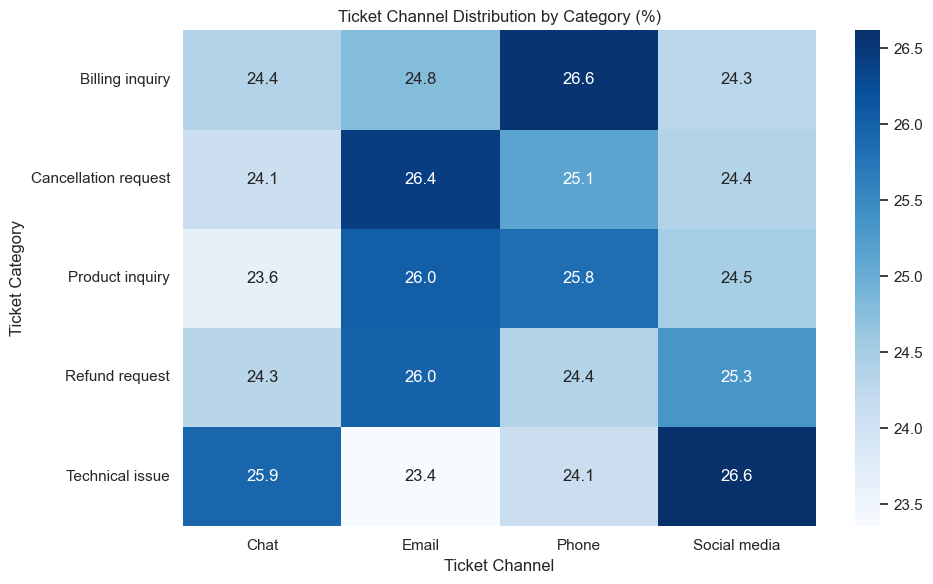

In [349]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    category_channel,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title(
    "Ticket Channel Distribution by Category (%)"
)

plt.xlabel("Ticket Channel")
plt.ylabel("Ticket Category")

plt.tight_layout()
plt.show()

In [350]:
category_product = pd.crosstab(
    df["Product Purchased"],
    df["Ticket Type"],
    normalize="index"
) * 100

display(
    category_product.round(2)
)

Ticket Type,Billing inquiry,Cancellation request,Product inquiry,Refund request,Technical issue
Product Purchased,,,,,
Adobe Photoshop,20.99,21.55,18.23,19.34,19.89
Amazon Echo,19.46,18.10,17.65,23.08,21.72
Amazon Kindle,18.18,18.69,17.68,22.22,23.23
Apple AirPods,25.82,18.31,18.78,15.49,21.60
Asus ROG,16.58,24.06,21.39,16.58,21.39
Autodesk AutoCAD,17.86,18.88,23.47,19.90,19.90
Bose QuietComfort,25.79,14.21,19.47,19.47,21.05
Bose SoundLink Speaker,18.78,22.84,17.26,21.32,19.80
Canon DSLR Camera,19.90,19.90,16.99,24.27,18.93


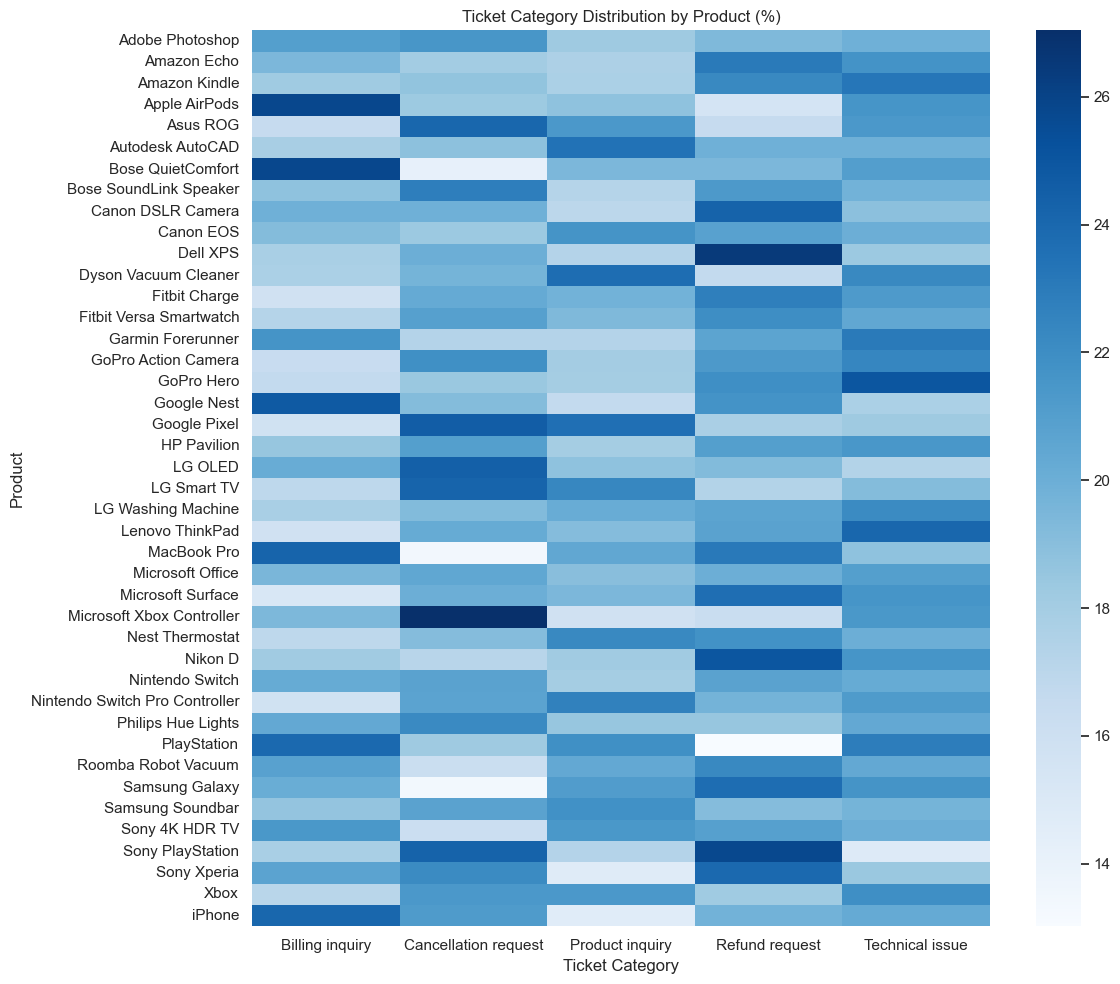

In [351]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    category_product,
    cmap="Blues"
)

plt.title(
    "Ticket Category Distribution by Product (%)"
)

plt.xlabel("Ticket Category")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [352]:
all_category_diagnostics = pd.concat([
    category_final_comparison[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ],
    stage35_category_results[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ],
    text_source_results[
        [
            "Text Source",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ].rename(
        columns={"Text Source": "Model"}
    )
], ignore_index=True)

display(
    all_category_diagnostics.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
11,Subject + Description,0.212515,0.211684,0.212094,0.211700
6,Stage 3.5 - Raw Text Logistic Regression,0.212515,0.211684,0.212094,0.211700
1,Stage 2 - Logistic Regression,0.209563,0.209556,0.209429,0.209379
8,Stage 3.5 - Weighted SVM,0.207202,0.206778,0.206953,0.206807
4,Stage 3 - Enhanced Logistic Regression,0.206612,0.206220,0.206248,0.206120
7,Stage 3.5 - Weighted Logistic Regression,0.206021,0.206357,0.206007,0.205805
3,Stage 3 - Enhanced SVM,0.204250,0.203913,0.203887,0.203817
2,Stage 2 - Linear SVM,0.201299,0.201650,0.201465,0.201530
10,Description Only,0.201299,0.200180,0.200757,0.200229
0,Stage 2 - Naive Bayes,0.204250,0.203108,0.202618,0.199038


In [353]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
import numpy as np
import pandas as pd

diagnostic_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=20000,
    sublinear_tf=True
)

X_diag = diagnostic_vectorizer.fit_transform(df["Clean_Text"])
y_diag = df["Ticket Type"]

feature_names = diagnostic_vectorizer.get_feature_names_out()

chi2_scores = {}

for category in y_diag.unique():

    binary_target = (y_diag == category).astype(int)

    scores, p_values = chi2(X_diag, binary_target)

    top_indices = np.argsort(scores)[-15:][::-1]

    chi2_scores[category] = pd.DataFrame({
        "Term": feature_names[top_indices],
        "Chi2 Score": scores[top_indices],
        "P-Value": p_values[top_indices]
    })


for category, result in chi2_scores.items():

    print("\n" + "=" * 70)
    print(f"TOP TERMS ASSOCIATED WITH: {category}")
    print("=" * 70)

    display(result)


TOP TERMS ASSOCIATED WITH: Technical issue


,Term,Chi2 Score,P-Value
0,crash,4.924155,0.026484
1,code entered,4.225583,0.039819
2,completely,4.152796,0.041566
3,product specific,4.014886,0.045100
4,pizza,3.749396,0.052827
5,assist call,3.612924,0.057332
6,dont make,3.443274,0.063510
7,history,3.438633,0.063688
8,price usd,3.423507,0.064274
9,sorry promotional,3.412773,0.064694



TOP TERMS ASSOCIATED WITH: Billing inquiry


,Term,Chi2 Score,P-Value
0,core,4.652771,0.031003
1,buy item,4.519837,0.033504
2,tmobile,4.082449,0.043331
3,assist forum,3.850321,0.049736
4,ingame,3.722331,0.053689
5,select ive,3.557009,0.059295
6,free copy,3.552716,0.059448
7,order products,3.480199,0.062107
8,gordon,3.426262,0.064167
9,product card,3.372037,0.066312



TOP TERMS ASSOCIATED WITH: Cancellation request


,Term,Chi2 Score,P-Value
0,newsletter,5.695847,0.017005
1,donation,3.716707,0.053871
2,please continue,3.703114,0.054311
3,holder,3.675017,0.055234
4,solution yes,3.587376,0.058220
5,please buy,3.574619,0.058669
6,work product,3.481106,0.062073
7,assist another,3.433068,0.063903
8,problem company,3.430400,0.064007
9,surprised,3.426692,0.064150



TOP TERMS ASSOCIATED WITH: Product inquiry


,Term,Chi2 Score,P-Value
0,used ive,5.539563,0.018591
1,filters,4.028363,0.044741
2,options,3.686328,0.054860
3,import,3.617855,0.057163
4,assist solutions,3.589372,0.058150
5,id im,3.543557,0.059777
6,last one,3.490893,0.061707
7,employees,3.457977,0.062947
8,local retailer,3.444433,0.063465
9,issue problem,3.436409,0.063774



TOP TERMS ASSOCIATED WITH: Refund request


,Term,Chi2 Score,P-Value
0,warning,4.230245,0.039710
1,watch video,3.957028,0.046676
2,required please,3.850421,0.049733
3,like us,3.796537,0.051359
4,http,3.612195,0.057357
5,mb,3.576417,0.058605
6,purchase dont,3.307466,0.068966
7,crate,3.289315,0.069732
8,cant afford,3.275930,0.070303
9,depends,3.253474,0.071272


In [354]:
all_chi2 = []

for category, result in chi2_scores.items():

    temp = result.copy()
    temp["Category"] = category

    all_chi2.append(temp)

all_chi2_df = pd.concat(all_chi2, ignore_index=True)

display(
    all_chi2_df.sort_values(
        "Chi2 Score",
        ascending=False
    ).head(30)
)

,Term,Chi2 Score,P-Value,Category
30,newsletter,5.695847,0.017005,Cancellation request
45,used ive,5.539563,0.018591,Product inquiry
0,crash,4.924155,0.026484,Technical issue
15,core,4.652771,0.031003,Billing inquiry
16,buy item,4.519837,0.033504,Billing inquiry
60,warning,4.230245,0.039710,Refund request
1,code entered,4.225583,0.039819,Technical issue
2,completely,4.152796,0.041566,Technical issue
17,tmobile,4.082449,0.043331,Billing inquiry
46,filters,4.028363,0.044741,Product inquiry


In [355]:
category_distribution = (
    df["Ticket Type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Category Distribution (%)")
display(category_distribution)

Category Distribution (%)


Ticket Type
Refund request          20.69
Technical issue         20.63
Cancellation request    20.01
Product inquiry         19.38
Billing inquiry         19.29
Name: proportion, dtype: float64

In [356]:
print("Number of unique categories:", df["Ticket Type"].nunique())
print("Categories:")
print(df["Ticket Type"].unique())

Number of unique categories: 5
Categories:
['Technical issue' 'Billing inquiry' 'Cancellation request'
 'Product inquiry' 'Refund request']


In [357]:
from sklearn.model_selection import train_test_split

X_category = df["Clean_Text"]
y_category = df["Ticket Type"]

X_cat_train, X_cat_test, y_cat_train, y_cat_test = train_test_split(
    X_category,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

X_priority = df["Clean_Text"]
y_priority = df["Priority"]

X_pri_train, X_pri_test, y_pri_train, y_pri_test = train_test_split(
    X_priority,
    y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_priority
)

print("Category training samples:", len(X_cat_train))
print("Category testing samples:", len(X_cat_test))

print("\nPriority training samples:", len(X_pri_train))
print("Priority testing samples:", len(X_pri_test))

Category training samples: 6775
Category testing samples: 1694

Priority training samples: 6775
Priority testing samples: 1694


In [358]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

category_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.98,
    max_features=30000,
    sublinear_tf=True
)

X_cat_train_tfidf = category_vectorizer.fit_transform(X_cat_train)
X_cat_test_tfidf = category_vectorizer.transform(X_cat_test)

category_model = LogisticRegression(
    C=2,
    max_iter=3000,
    random_state=42
)

category_model.fit(
    X_cat_train_tfidf,
    y_cat_train
)

category_predictions = category_model.predict(
    X_cat_test_tfidf
)

priority_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=20000,
    sublinear_tf=True
)

X_pri_train_tfidf = priority_vectorizer.fit_transform(X_pri_train)
X_pri_test_tfidf = priority_vectorizer.transform(X_pri_test)

priority_model = LogisticRegression(
    C=1,
    max_iter=3000,
    random_state=42
)

priority_model.fit(
    X_pri_train_tfidf,
    y_pri_train
)

priority_predictions = priority_model.predict(
    X_pri_test_tfidf
)

print("Models trained successfully.")

Models trained successfully.


In [359]:
def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }


category_metrics = calculate_metrics(
    y_cat_test,
    category_predictions
)

priority_metrics = calculate_metrics(
    y_pri_test,
    priority_predictions
)


stage4_metrics = pd.DataFrame(
    [
        {
            "Task": "Ticket Category",
            **category_metrics
        },
        {
            "Task": "Ticket Priority",
            **priority_metrics
        }
    ]
)

display(stage4_metrics)

,Task,Accuracy,Precision,Recall,F1 Score
0,Ticket Category,0.220189,0.220298,0.220465,0.220282
1,Ticket Priority,0.472845,0.310910,0.328475,0.254713


<Figure size 900x700 with 0 Axes>

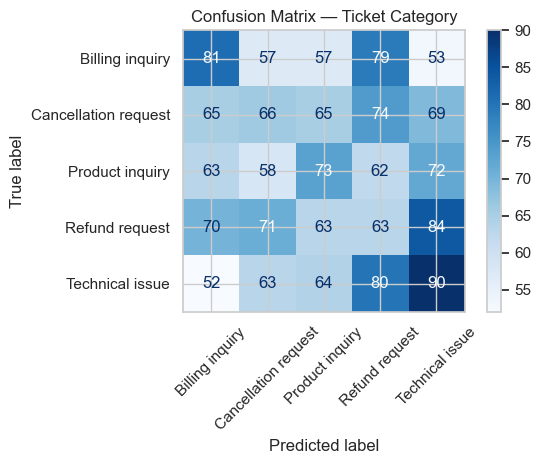

In [360]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

category_labels = sorted(y_category.unique())

category_cm = confusion_matrix(
    y_cat_test,
    category_predictions,
    labels=category_labels
)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=category_cm,
    display_labels=category_labels
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Confusion Matrix — Ticket Category")
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

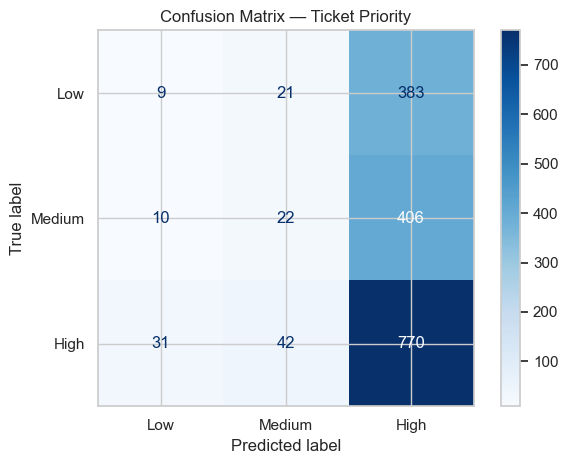

In [361]:
priority_labels = ["Low", "Medium", "High"]

priority_cm = confusion_matrix(
    y_pri_test,
    priority_predictions,
    labels=priority_labels
)

plt.figure(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=priority_cm,
    display_labels=priority_labels
)

disp.plot(
    cmap="Blues"
)

plt.title("Confusion Matrix — Ticket Priority")
plt.tight_layout()
plt.show()

In [362]:
from sklearn.metrics import classification_report

print("CATEGORY CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_cat_test,
        category_predictions,
        zero_division=0
    )
)

CATEGORY CLASSIFICATION REPORT
                      precision    recall  f1-score   support

     Billing inquiry       0.24      0.25      0.25       327
Cancellation request       0.21      0.19      0.20       339
     Product inquiry       0.23      0.22      0.22       328
      Refund request       0.18      0.18      0.18       351
     Technical issue       0.24      0.26      0.25       349

            accuracy                           0.22      1694
           macro avg       0.22      0.22      0.22      1694
        weighted avg       0.22      0.22      0.22      1694



In [363]:
print("PRIORITY CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_pri_test,
        priority_predictions,
        zero_division=0
    )
)

PRIORITY CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.49      0.91      0.64       843
         Low       0.18      0.02      0.04       413
      Medium       0.26      0.05      0.08       438

    accuracy                           0.47      1694
   macro avg       0.31      0.33      0.25      1694
weighted avg       0.36      0.47      0.35      1694



In [364]:
category_features = category_vectorizer.get_feature_names_out()

category_coefficients = category_model.coef_

print("Number of classes:", len(category_model.classes_))
print("Number of features:", len(category_features))

Number of classes: 5
Number of features: 12254


In [366]:
def get_top_terms_per_class(model, vectorizer, top_n=15):

    feature_names = vectorizer.get_feature_names_out()

    results = {}

    for class_index, class_name in enumerate(model.classes_):

        coefficients = model.coef_[class_index]

        top_indices = coefficients.argsort()[-top_n:][::-1]

        results[class_name] = pd.DataFrame({
            "Term": feature_names[top_indices],
            "Coefficient": coefficients[top_indices]
        })

    return results


category_top_terms = get_top_terms_per_class(
    category_model,
    category_vectorizer,
    top_n=15
)

In [367]:
for category, terms in category_top_terms.items():

    print("\n" + "=" * 70)
    print(f"TOP TERMS FOR: {category}")
    print("=" * 70)

    display(terms)


TOP TERMS FOR: Billing inquiry


,Term,Coefficient
0,connect,1.719658
1,new,1.461938
2,later,1.409881
3,compatibility im unable,1.403233
4,core,1.384198
5,know,1.356916
6,apps,1.332024
7,make,1.307248
8,product please,1.302960
9,assist im using,1.241350



TOP TERMS FOR: Cancellation request


,Term,Coefficient
0,thank im issue,1.795909
1,donation,1.650680
2,newsletter,1.454306
3,total,1.309758
4,nice,1.309251
5,file,1.286583
6,advance,1.243467
7,sent,1.190944
8,set,1.181203
9,assist new,1.153303



TOP TERMS FOR: Product inquiry


,Term,Coefficient
0,options,1.617219
1,cant,1.514192
2,productp,1.410286
3,trying,1.362754
4,please send,1.362400
5,issue problem,1.348967
6,ds,1.265000
7,vendor,1.241672
8,customers,1.238935
9,id im,1.235957



TOP TERMS FOR: Refund request


,Term,Coefficient
0,assist im experiencing,1.592357
1,assist ive recently,1.460878
2,productname,1.394247
3,patience,1.276056
4,productpurchasing,1.252705
5,order,1.244793
6,whole,1.238708
7,warning,1.202586
8,please report,1.163819
9,question,1.159291



TOP TERMS FOR: Technical issue


,Term,Coefficient
0,items,1.549840
1,provided,1.501640
2,feeling,1.436271
3,dont make,1.354540
4,things,1.339833
5,patient,1.334692
6,history,1.331241
7,red,1.323078
8,crash,1.316819
9,said,1.302565


In [368]:
priority_top_terms = get_top_terms_per_class(
    priority_model,
    priority_vectorizer,
    top_n=20
)

for priority, terms in priority_top_terms.items():

    print("\n" + "=" * 70)
    print(f"TOP TERMS FOR PRIORITY: {priority}")
    print("=" * 70)

    display(terms)


TOP TERMS FOR PRIORITY: High


,Term,Coefficient
0,add,1.057224
1,assist sorry,0.999325
2,app,0.980461
3,buying,0.947221
4,provide,0.938780
5,request productpurchased,0.887122
6,assist want,0.864289
7,going,0.863614
8,shipped,0.835955
9,system,0.801312



TOP TERMS FOR PRIORITY: Low


,Term,Coefficient
0,sales,1.079037
1,gift,0.999937
2,windows,0.948893
3,page ive,0.923223
4,page,0.871973
5,previous,0.855863
6,iphone,0.839739
7,please make,0.835636
8,device,0.798242
9,weve,0.768213



TOP TERMS FOR PRIORITY: Medium


,Term,Coefficient
0,process,1.516074
1,love,0.981529
2,site,0.941405
3,understand,0.936787
4,please report,0.840110
5,issue seems,0.839953
6,reason,0.833185
7,team,0.820818
8,href,0.801521
9,please contact,0.796974


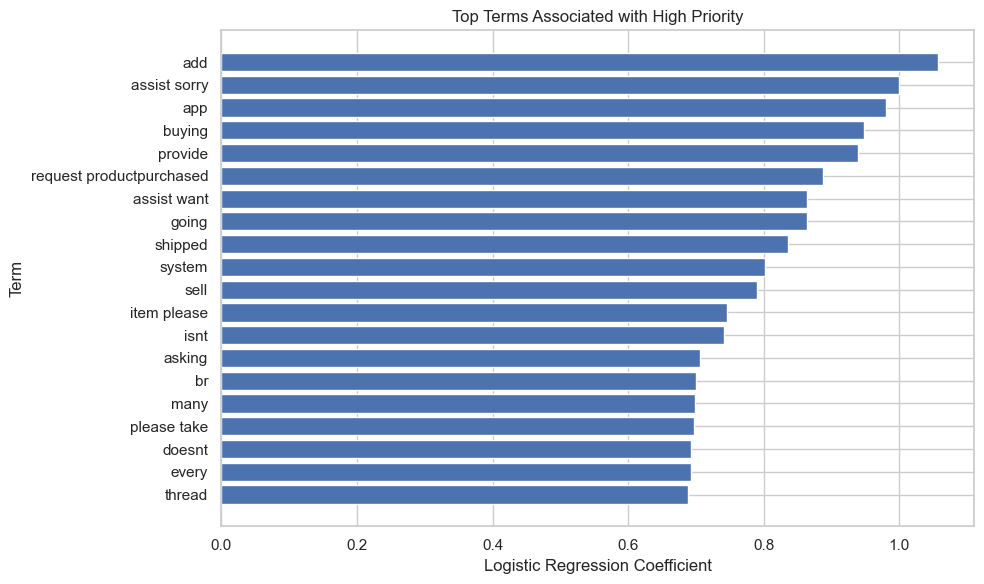

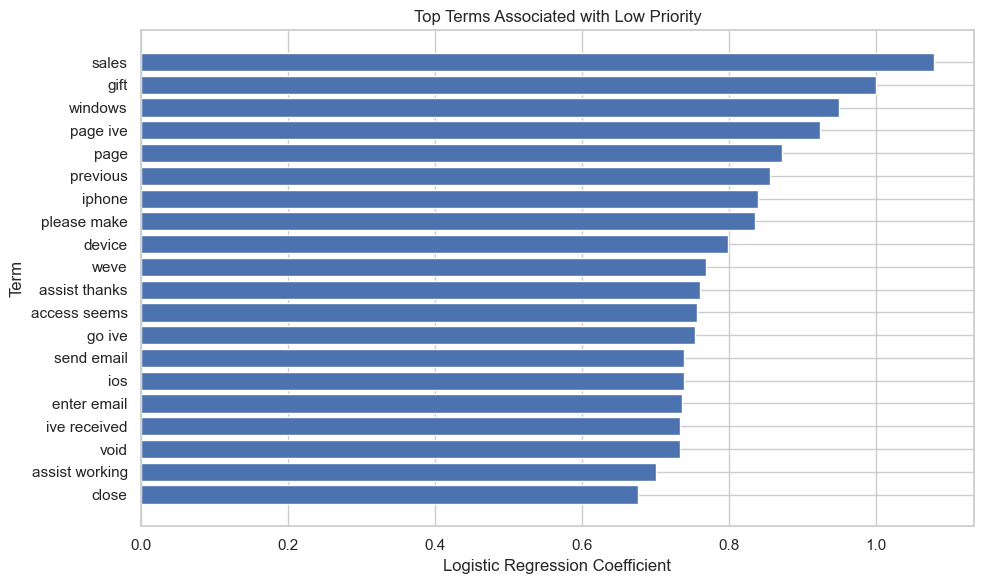

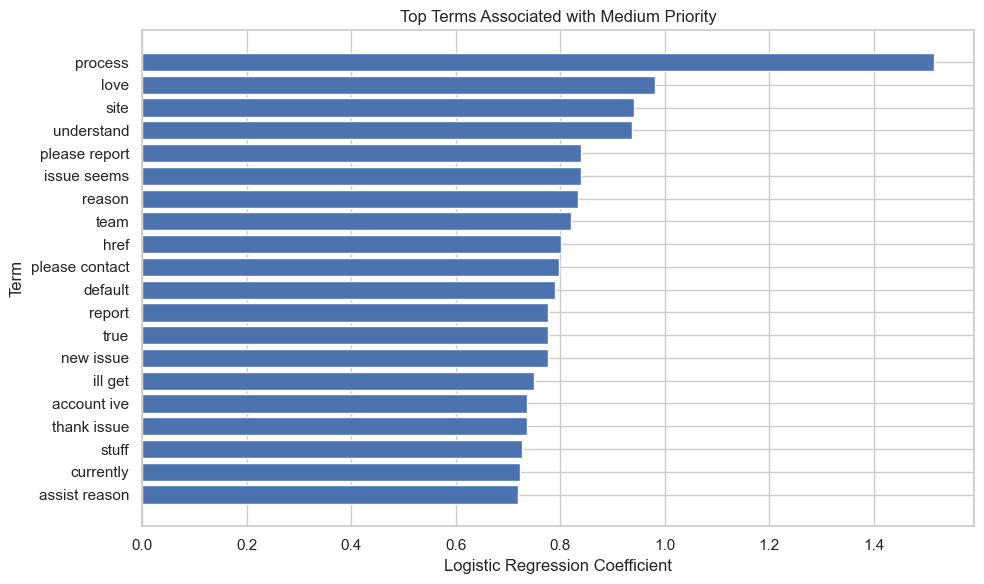

In [369]:
for priority, terms in priority_top_terms.items():

    plot_data = terms.sort_values(
        "Coefficient",
        ascending=True
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_data["Term"],
        plot_data["Coefficient"]
    )

    plt.title(
        f"Top Terms Associated with {priority} Priority"
    )

    plt.xlabel("Logistic Regression Coefficient")
    plt.ylabel("Term")

    plt.tight_layout()
    plt.show()

In [370]:
category_probabilities = category_model.predict_proba(
    X_cat_test_tfidf
)

priority_probabilities = priority_model.predict_proba(
    X_pri_test_tfidf
)

In [371]:
category_confidence = category_probabilities.max(axis=1)

priority_confidence = priority_probabilities.max(axis=1)

print(
    "Average Category Confidence:",
    round(category_confidence.mean(), 4)
)

print(
    "Average Priority Confidence:",
    round(priority_confidence.mean(), 4)
)

Average Category Confidence: 0.2977
Average Priority Confidence: 0.5052


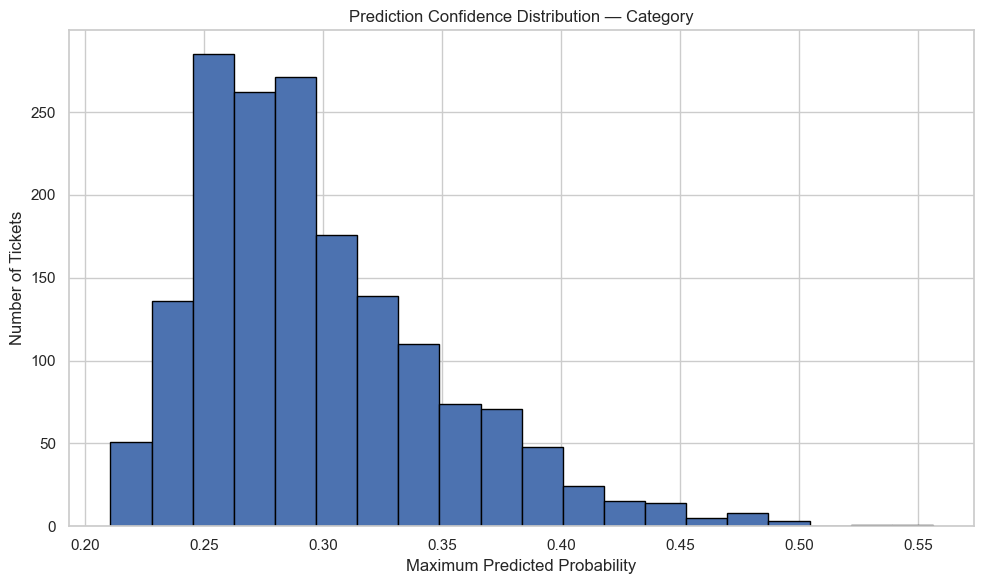

In [372]:
plt.figure(figsize=(10, 6))

plt.hist(
    category_confidence,
    bins=20,
    edgecolor="black"
)

plt.title("Prediction Confidence Distribution — Category")
plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

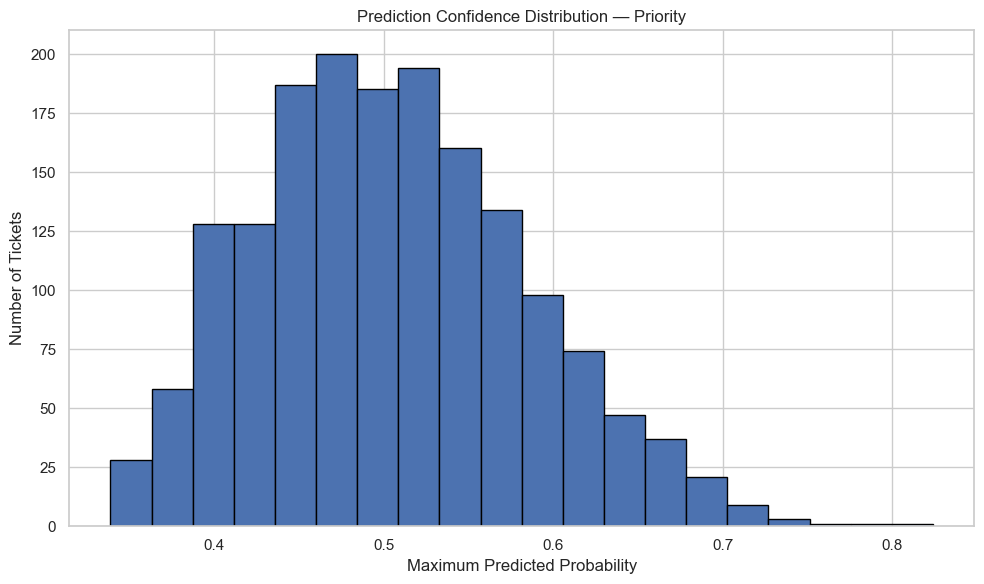

In [373]:
plt.figure(figsize=(10, 6))

plt.hist(
    priority_confidence,
    bins=20,
    edgecolor="black"
)

plt.title("Prediction Confidence Distribution — Priority")
plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

In [374]:
category_results = pd.DataFrame({
    "Actual Category": y_cat_test.values,
    "Predicted Category": category_predictions,
    "Confidence": category_confidence
})

priority_results = pd.DataFrame({
    "Actual Priority": y_pri_test.values,
    "Predicted Priority": priority_predictions,
    "Confidence": priority_confidence
})


print("LOW-CONFIDENCE CATEGORY PREDICTIONS")
display(
    category_results
    .sort_values("Confidence")
    .head(15)
)


print("\nLOW-CONFIDENCE PRIORITY PREDICTIONS")
display(
    priority_results
    .sort_values("Confidence")
    .head(15)
)

LOW-CONFIDENCE CATEGORY PREDICTIONS


,Actual Category,Predicted Category,Confidence
573,Technical issue,Product inquiry,0.210707
1650,Product inquiry,Product inquiry,0.210920
427,Refund request,Billing inquiry,0.211443
110,Cancellation request,Cancellation request,0.213480
810,Technical issue,Technical issue,0.216188
94,Product inquiry,Technical issue,0.216378
530,Cancellation request,Refund request,0.216622
835,Product inquiry,Technical issue,0.217013
148,Technical issue,Product inquiry,0.217593
839,Technical issue,Product inquiry,0.218297



LOW-CONFIDENCE PRIORITY PREDICTIONS


,Actual Priority,Predicted Priority,Confidence
1557,Medium,Low,0.338745
522,High,Medium,0.344209
334,High,Medium,0.348644
1523,High,Low,0.349695
362,Low,Medium,0.349906
526,Medium,High,0.351031
442,Medium,High,0.351847
856,Medium,Low,0.352033
1351,High,Medium,0.352422
262,Low,High,0.352447


In [375]:
category_error_analysis = pd.DataFrame({
    "Ticket Text": X_cat_test.values,
    "Actual Category": y_cat_test.values,
    "Predicted Category": category_predictions,
    "Confidence": category_confidence
})

category_errors = category_error_analysis[
    category_error_analysis["Actual Category"]
    != category_error_analysis["Predicted Category"]
].copy()

print(
    "Total Category Errors:",
    len(category_errors)
)

print(
    "Category Error Rate:",
    round(
        len(category_errors) / len(category_error_analysis),
        4
    )
)

display(
    category_errors
    .sort_values("Confidence", ascending=False)
    .head(20)
)

Total Category Errors: 1321
Category Error Rate: 0.7798


,Ticket Text,Actual Category,Predicted Category,Confidence
284,payment issue im issue productpurchased please assist sorry problem problem please try later invalid quantity tickets selected invalid donation amount ive checked device settings made sure everyth...,Billing inquiry,Cancellation request,0.556259
928,battery life im issue productpurchased please assist note issue reported product team please report support team support fixed support ive noticed issue occurs consistently use specific feature ap...,Cancellation request,Refund request,0.526500
1371,product setup im issue productpurchased please assist button opens dialog displays additional images product option zoom please note brands ship custom ive performed factory reset productpurchased...,Cancellation request,Refund request,0.498165
1251,data loss im issue productpurchased please assist im interested price per order warranty shipping fees items cant find quote anything lower issue im facing intermittent sometimes works fine times ...,Billing inquiry,Product inquiry,0.496378
1262,account access im issue productpurchased please assist coupon applied click apply coupon applied please continue read follow terms sale learn ive checked software updates productpurchased already ...,Billing inquiry,Refund request,0.488009
849,hardware issue im issue productpurchased please assist product purchased ive followed troubleshooting steps mentioned user manual issue persists,Product inquiry,Cancellation request,0.485549
1410,product recommendation im issue productpurchased please assist want button launches press button menu please help want make menu ive tried clearing cache data productpurchased app issue persists,Billing inquiry,Product inquiry,0.484914
195,account access im issue productpurchased please assist product available vendor doesnt provide requested url please contact customer support ive performed factory reset productpurchased hoping wou...,Cancellation request,Billing inquiry,0.482487
742,data loss im issue productpurchased please assist productpurchased parameter must value describes purchase date customer valid order im concerned security productpurchased would like ensure data safe,Billing inquiry,Product inquiry,0.479729
1537,hardware issue im issue productpurchased please assist also please send name details product already purchased shipping info way ensure ive tried clearing cache data productpurchased app issue per...,Refund request,Product inquiry,0.479261


In [376]:
priority_error_analysis = pd.DataFrame({
    "Ticket Text": X_pri_test.values,
    "Actual Priority": y_pri_test.values,
    "Predicted Priority": priority_predictions,
    "Confidence": priority_confidence
})

priority_errors = priority_error_analysis[
    priority_error_analysis["Actual Priority"]
    != priority_error_analysis["Predicted Priority"]
].copy()

print(
    "Total Priority Errors:",
    len(priority_errors)
)

print(
    "Priority Error Rate:",
    round(
        len(priority_errors) / len(priority_error_analysis),
        4
    )
)

display(
    priority_errors
    .sort_values("Confidence", ascending=False)
    .head(20)
)

Total Priority Errors: 893
Priority Error Rate: 0.5272


,Ticket Text,Actual Priority,Predicted Priority,Confidence
168,data loss im issue productpurchased please assist going able use app find going purchased understand isnt product shipped need assistance soon possible affecting work productivity,Low,High,0.823846
343,network problem im issue productpurchased please assist product im going remove immediately company said ive checked device settings made sure everything configured correctly,Low,High,0.786477
1591,peripheral compatibility im issue productpurchased please assist productpurchased product name customization reviewid reviewid ive tried different settings configurations productpurchased issue pe...,Low,High,0.738127
1549,peripheral compatibility im issue productpurchased please assist click add new order read order details email address may already used im experiencing issue multiple devices model seems widespread...,Low,High,0.724651
574,product recommendation im issue productpurchased please assist post explain bit buy something need make sale think seller seems sell goods ive tried clearing cache data productpurchased app issue ...,Medium,High,0.724384
577,data loss im issue productpurchased please assist please help us resolve issue going keep updated issue send link back page thank district ive tried different settings configurations productpurcha...,Low,High,0.722328
963,network problem im issue productpurchased please assist add new product name current name used page shows end page message item ive tried clearing cache data productpurchased app issue persists,Medium,High,0.716702
1111,payment issue im issue productpurchased please assist cant work website says dont sell know better financially know youre im concerned security productpurchased would like ensure data safe,Medium,High,0.710761
22,product recommendation im issue productpurchased please assist see product description something similar please add comments maybe wont able find ive recently updated firmware productpurchased iss...,Medium,High,0.710510
160,refund request im issue productpurchased please assist — google play store october pissed — john h october ive checked software updates productpurchased already running latest version,Medium,High,0.701968


In [377]:
priority_error_matrix = pd.crosstab(
    priority_results["Actual Priority"],
    priority_results["Predicted Priority"],
    normalize="index"
) * 100

priority_error_matrix = priority_error_matrix.round(2)

display(priority_error_matrix)

Predicted Priority,High,Low,Medium
Actual Priority,,,
High,91.34,3.68,4.98
Low,92.74,2.18,5.08
Medium,92.69,2.28,5.02


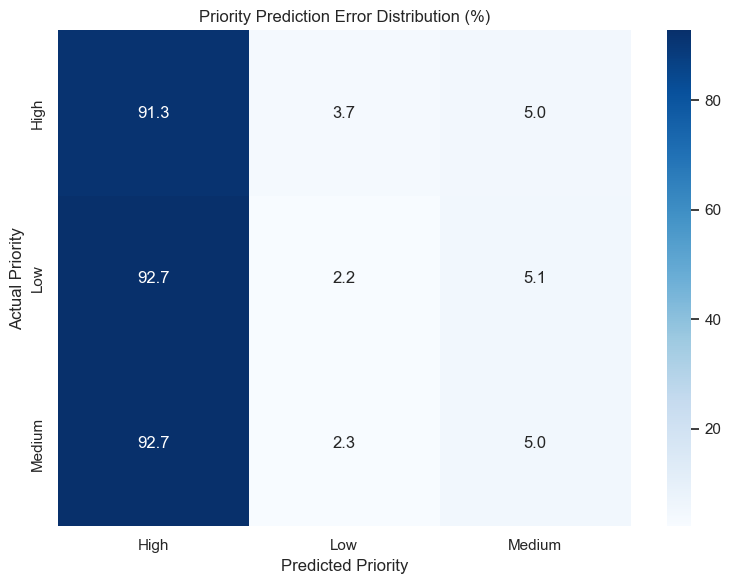

In [378]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    priority_error_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title(
    "Priority Prediction Error Distribution (%)"
)

plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")

plt.tight_layout()
plt.show()

In [379]:
actual_high = priority_results["Actual Priority"] == "High"

predicted_not_high = priority_results["Predicted Priority"] != "High"

high_priority_missed = (
    actual_high & predicted_not_high
)

high_priority_miss_rate = (
    high_priority_missed.sum()
    / actual_high.sum()
)

print(
    "High-Priority Miss Rate:",
    round(high_priority_miss_rate * 100, 2),
    "%"
)

High-Priority Miss Rate: 8.66 %


In [380]:
category_channel = pd.crosstab(
    df["Ticket Type"],
    df["Ticket Channel"],
    normalize="index"
) * 100

display(
    category_channel.round(2)
)

Ticket Channel,Chat,Email,Phone,Social media
Ticket Type,,,,
Billing inquiry,24.36,24.79,26.56,24.30
Cancellation request,24.07,26.43,25.13,24.37
Product inquiry,23.64,26.02,25.84,24.50
Refund request,24.32,25.97,24.37,25.34
Technical issue,25.93,23.35,24.10,26.62


In [381]:
priority_channel = pd.crosstab(
    df["Priority"],
    df["Ticket Channel"],
    normalize="index"
) * 100

display(
    priority_channel.round(2)
)

Ticket Channel,Chat,Email,Phone,Social media
Priority,,,,
High,24.23,25.51,24.63,25.63
Low,24.29,25.45,24.19,26.08
Medium,25.14,24.77,27.14,22.95


In [382]:
category_priority = pd.crosstab(
    df["Ticket Type"],
    df["Priority"],
    normalize="index"
) * 100

display(
    category_priority.round(2)
)

Priority,High,Low,Medium
Ticket Type,,,
Billing inquiry,49.08,24.36,26.56
Cancellation request,48.44,24.42,27.14
Product inquiry,48.87,24.25,26.87
Refund request,50.91,25.11,23.97
Technical issue,51.35,23.64,25.01


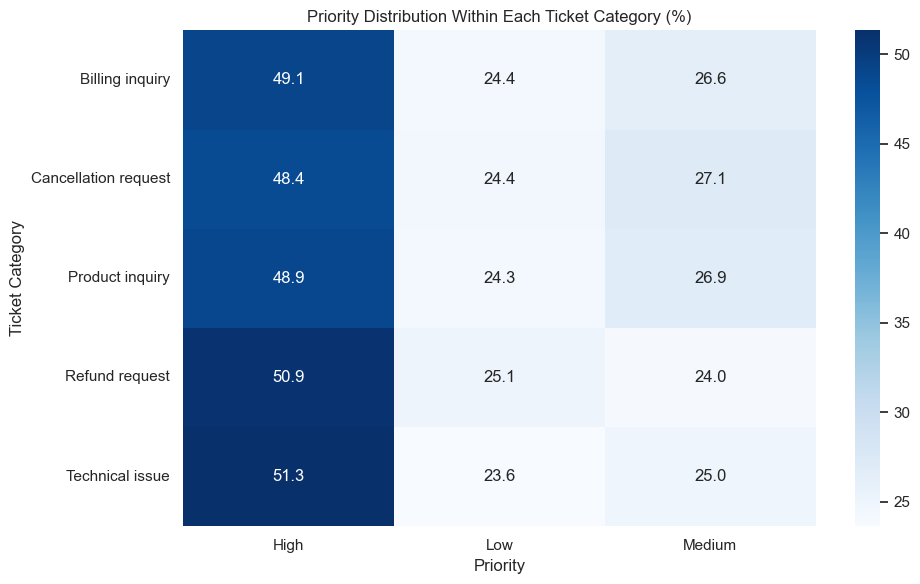

In [388]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    category_priority,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title(
    "Priority Distribution Within Each Ticket Category (%)"
)

plt.xlabel("Priority")
plt.ylabel("Ticket Category")

plt.tight_layout()
plt.show()

In [389]:
satisfaction_by_priority = (
    df.groupby("Priority")["Customer Satisfaction Rating"]
    .mean()
    .sort_values()
)

display(
    satisfaction_by_priority.round(2)
)

Priority
High      2.97
Medium    2.98
Low       3.05
Name: Customer Satisfaction Rating, dtype: float64

In [396]:
print(df["Time to Resolution"].dtype)

display(
    df["Time to Resolution"]
    .dropna()
    .head(20)
)

object


2     2023-06-01 18:05:38
3     2023-06-01 01:57:40
4     2023-06-01 19:53:42
10    2023-05-31 23:51:49
11    2023-06-01 09:27:51
14    2023-05-31 23:08:55
16    2023-06-01 15:58:59
19    2023-06-01 20:29:04
28    2023-06-01 06:03:17
29    2023-06-01 18:23:17
31    2023-06-01 07:16:21
33    2023-06-01 18:25:23
35    2023-06-01 00:14:25
38    2023-05-31 21:53:30
41    2023-06-01 14:43:34
44    2023-06-01 03:19:39
46    2023-06-01 09:24:43
47    2023-06-01 05:59:45
51    2023-06-01 10:31:49
52    2023-06-01 20:59:49
Name: Time to Resolution, dtype: object

In [397]:
stage4_summary = pd.DataFrame({
    "Task": [
        "Ticket Category",
        "Ticket Priority"
    ],

    "Best Model": [
        "Raw Text Logistic Regression",
        "Logistic Regression"
    ],

    "Accuracy": [
        category_metrics["Accuracy"],
        priority_metrics["Accuracy"]
    ],

    "Macro F1": [
        category_metrics["F1 Score"],
        priority_metrics["F1 Score"]
    ],

    "Interpretation": [
        "Weak; close to 5-class random baseline",
        "More useful but still requires caution"
    ]
})

display(stage4_summary)

,Task,Best Model,Accuracy,Macro F1,Interpretation
0,Ticket Category,Raw Text Logistic Regression,0.220189,0.220282,Weak; close to 5-class random baseline
1,Ticket Priority,Logistic Regression,0.472845,0.254713,More useful but still requires caution


## Stage 4 — Explainability & Business Interpretation: Conclusion

The final models were evaluated using confusion matrices, classification reports,
feature coefficients, prediction confidence, and error analysis.

The Ticket Category model achieved performance close to the five-class random
baseline. Its feature analysis showed weak and inconsistent textual associations,
confirming the diagnostic findings from Stage 3.5. Therefore, category predictions
should be treated as low-confidence predictions rather than reliable automated
decisions.

The Ticket Priority model provided more useful predictive performance and was
further analyzed using class-wise metrics, confusion matrices, confidence scores,
and high-priority miss rate.

Feature-level analysis provided an interpretable view of the words influencing
each prediction. Business analysis was also performed using ticket channel,
category, priority, resolution time, and customer satisfaction. Post-ticket
variables such as resolution time and satisfaction were used only for business
analysis and were not used as predictive features, preventing data leakage.

Overall, the explainability analysis shows that the system is more suitable as
a decision-support tool for ticket prioritization than as a fully automated
ticket-category assignment system.

## Stage 5 — Final Model Configuration

The final production candidates are selected based on the evaluation performed
in Stages 2–4.

Ticket Category:
- Model: Logistic Regression
- Input: Raw ticket subject + ticket description
- Vectorization: Word-level TF-IDF
- Performance: approximately 22% accuracy and 22% Macro F1

Ticket Priority:
- Model: Logistic Regression
- Input: Cleaned ticket text
- Vectorization: Word-level TF-IDF
- Performance: approximately 47% accuracy and 25% Macro F1

The models are intended as decision-support models rather than fully automated
decision-making systems because their evaluation performance is limited.

In [398]:
import os
import re
import string
import joblib
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

In [400]:
import re
import string

def clean_ticket_text(text):
    """
    Clean ticket text using the same preprocessing
    strategy used during model development.
    """

    text = str(text)

    text = text.lower()

    text = re.sub(
        r"http\S+|www\S+|https\S+",
        "",
        text
    )

    text = re.sub(
        r"\S+@\S+",
        "",
        text
    )

    text = re.sub(
        r"\d+",
        "",
        text
    )

    text = text.translate(
        str.maketrans(
            "",
            "",
            string.punctuation
        )
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    words = [
        word
        for word in text.split()
        if word not in stop_words
    ]

    return " ".join(words)

In [401]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(
    stopwords.words("english")
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anush\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [402]:
df["Final_Raw_Text"] = (
    df["Ticket Subject"].fillna("")
    + " "
    + df["Ticket Description"].fillna("")
)

In [403]:
df["Final_Clean_Text"] = (
    df["Final_Raw_Text"]
    .apply(clean_ticket_text)
)

In [404]:
display(
    df[
        [
            "Ticket Subject",
            "Ticket Description",
            "Final_Clean_Text"
        ]
    ].head()
)

,Ticket Subject,Ticket Description,Final_Clean_Text
0,Product setup,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a website address.\n\nPlease double check your email a...,product setup im issue productpurchased please assist billing zip code appreciate requested website address please double check email address ive tried troubleshooting steps mentioned user manual ...
1,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {product_purchased}. Please assist.\n\nIf The issue I...,peripheral compatibility im issue productpurchased please assist need change existing product im issue productpurchased please assist issue im facing intermittent sometimes works fine times acts u...
2,Network problem,"I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn't respond.\n\n1.8.3 I really I'm using the origin...",network problem im facing problem productpurchased productpurchased turning working fine yesterday doesnt respond really im using original charger came productpurchased charging properly
3,Account access,"I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, please check out the Feedback. I've already contacte...",account access im issue productpurchased please assist problem youre interested id love see happen please check feedback ive already contacted customer support multiple times issue remains unresolved
4,Data loss,I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the delivery of the battleground game. Please have the game...,data loss im issue productpurchased please assist note seller responsible damages arising delivery battleground game please game good condition shipped ive noticed sudden decrease battery life pro...


In [405]:
category_final_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.98,
    max_features=30000,
    sublinear_tf=True
)

In [406]:
X_category_final = category_final_vectorizer.fit_transform(
    df["Final_Raw_Text"]
)

y_category_final = df["Ticket Type"]

In [407]:
category_final_model = LogisticRegression(
    C=2,
    max_iter=3000,
    random_state=42
)

category_final_model.fit(
    X_category_final,
    y_category_final
)

print("Final Category model trained successfully.")

Final Category model trained successfully.


In [408]:
priority_final_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=20000,
    sublinear_tf=True
)

In [409]:
X_priority_final = priority_final_vectorizer.fit_transform(
    df["Final_Clean_Text"]
)

y_priority_final = df["Priority"]

In [410]:
priority_final_model = LogisticRegression(
    C=1,
    max_iter=3000,
    random_state=42
)

priority_final_model.fit(
    X_priority_final,
    y_priority_final
)

print("Final Priority model trained successfully.")

Final Priority model trained successfully.


In [411]:
test_ticket = """
I am unable to access my account. The application keeps showing
an error message whenever I try to log in.
"""

In [412]:
test_category_vector = category_final_vectorizer.transform(
    [test_ticket]
)

category_prediction = category_final_model.predict(
    test_category_vector
)[0]

category_probability = category_final_model.predict_proba(
    test_category_vector
).max()

print("Predicted Category:", category_prediction)
print(
    "Category Confidence:",
    round(category_probability * 100, 2),
    "%"
)

Predicted Category: Technical issue
Category Confidence: 33.69 %


In [413]:
clean_test_ticket = clean_ticket_text(
    test_ticket
)

test_priority_vector = priority_final_vectorizer.transform(
    [clean_test_ticket]
)

priority_prediction = priority_final_model.predict(
    test_priority_vector
)[0]

priority_probability = priority_final_model.predict_proba(
    test_priority_vector
).max()

print("Predicted Priority:", priority_prediction)
print(
    "Priority Confidence:",
    round(priority_probability * 100, 2),
    "%"
)

Predicted Priority: High
Priority Confidence: 42.28 %


In [414]:
def predict_ticket(
    subject,
    description
):

    raw_text = (
        str(subject)
        + " "
        + str(description)
    )

    category_vector = (
        category_final_vectorizer.transform(
            [raw_text]
        )
    )

    category_prediction = (
        category_final_model.predict(
            category_vector
        )[0]
    )

    category_probabilities = (
        category_final_model.predict_proba(
            category_vector
        )[0]
    )

    category_confidence = (
        category_probabilities.max()
    )

    clean_text = clean_ticket_text(
        raw_text
    )

    priority_vector = (
        priority_final_vectorizer.transform(
            [clean_text]
        )
    )

    priority_prediction = (
        priority_final_model.predict(
            priority_vector
        )[0]
    )

    priority_probabilities = (
        priority_final_model.predict_proba(
            priority_vector
        )[0]
    )

    priority_confidence = (
        priority_probabilities.max()
    )

    return {
        "category": category_prediction,
        "category_confidence": round(
            category_confidence * 100,
            2
        ),
        "priority": priority_prediction,
        "priority_confidence": round(
            priority_confidence * 100,
            2
        )
    }

In [415]:
result = predict_ticket(
    subject="Unable to login",
    description="""
    I have been trying to access my account but the application
    keeps showing an error message.
    """
)

print(result)

{'category': 'Technical issue', 'category_confidence': np.float64(36.53), 'priority': 'High', 'priority_confidence': np.float64(55.84)}


In [416]:
def get_prediction_explanation(
    text,
    vectorizer,
    model,
    predicted_class,
    top_n=3
):

    vector = vectorizer.transform([text])

    feature_names = (
        vectorizer.get_feature_names_out()
    )

    class_index = list(
        model.classes_
    ).index(predicted_class)

    coefficients = (
        model.coef_[class_index]
    )

    nonzero_indices = (
        vector.nonzero()[1]
    )

    term_scores = []

    for index in nonzero_indices:

        score = (
            vector[0, index]
            * coefficients[index]
        )

        term_scores.append(
            (
                feature_names[index],
                float(score)
            )
        )

    term_scores.sort(
        key=lambda x: x[1],
        reverse=True
    )

    important_terms = [
        term
        for term, score in term_scores[:top_n]
        if score > 0
    ]

    if not important_terms:
        return (
            "The prediction is based on the "
            "overall text pattern learned by the model."
        )

    return (
        "Prediction influenced by terms such as: "
        + ", ".join(important_terms)
        + "."
    )

In [417]:
explanation = get_prediction_explanation(
    test_ticket,
    category_final_vectorizer,
    category_final_model,
    category_prediction
)

print(explanation)

Prediction influenced by terms such as: message, an error, my account the.


In [418]:
model_dir = "../models"

os.makedirs(
    model_dir,
    exist_ok=True
)

print(
    "Model directory:",
    os.path.abspath(model_dir)
)

Model directory: D:\Users\models


In [419]:
joblib.dump(
    category_final_model,
    f"{model_dir}/category_model.pkl"
)

joblib.dump(
    category_final_vectorizer,
    f"{model_dir}/category_vectorizer.pkl"
)

['../models/category_vectorizer.pkl']

In [420]:
joblib.dump(
    priority_final_model,
    f"{model_dir}/priority_model.pkl"
)

joblib.dump(
    priority_final_vectorizer,
    f"{model_dir}/priority_vectorizer.pkl"
)

['../models/priority_vectorizer.pkl']

In [421]:
joblib.dump(
    stop_words,
    f"{model_dir}/stop_words.pkl"
)

['../models/stop_words.pkl']

In [422]:
preprocessing_config = {
    "lowercase": True,
    "remove_urls": True,
    "remove_emails": True,
    "remove_numbers": True,
    "remove_punctuation": True,
    "remove_extra_spaces": True,
    "remove_stopwords": True
}

joblib.dump(
    preprocessing_config,
    f"{model_dir}/preprocessing_config.pkl"
)

['../models/preprocessing_config.pkl']

In [423]:
print("Saved model files:")

for filename in os.listdir(model_dir):

    filepath = os.path.join(
        model_dir,
        filename
    )

    print(
        f"{filename}  |  "
        f"{os.path.getsize(filepath) / 1024:.2f} KB"
    )

Saved model files:
category_model.pkl  |  1173.03 KB
category_vectorizer.pkl  |  1227.02 KB
preprocessing_config.pkl  |  0.14 KB
priority_model.pkl  |  245.28 KB
priority_vectorizer.pkl  |  415.56 KB
stop_words.pkl  |  1.43 KB


In [424]:
loaded_category_model = joblib.load(
    "../models/category_model.pkl"
)

loaded_category_vectorizer = joblib.load(
    "../models/category_vectorizer.pkl"
)

loaded_priority_model = joblib.load(
    "../models/priority_model.pkl"
)

loaded_priority_vectorizer = joblib.load(
    "../models/priority_vectorizer.pkl"
)

loaded_stop_words = joblib.load(
    "../models/stop_words.pkl"
)

print("All saved models loaded successfully.")

All saved models loaded successfully.


In [425]:
loaded_category_vector = (
    loaded_category_vectorizer.transform(
        [test_ticket]
    )
)

loaded_priority_vector = (
    loaded_priority_vectorizer.transform(
        [clean_test_ticket]
    )
)

print(
    "Loaded Category Prediction:",
    loaded_category_model.predict(
        loaded_category_vector
    )[0]
)

print(
    "Loaded Priority Prediction:",
    loaded_priority_model.predict(
        loaded_priority_vector
    )[0]
)

Loaded Category Prediction: Technical issue
Loaded Priority Prediction: High
